# Flood Probability Prediction — 多元線性回歸（CRISP-DM）

- **學號**：5115056015　**姓名**：鍾易憲　**課程**：物聯網應用與資料分析
- **資料集**：Kaggle Playground Series S4E5 — *Regression with a Flood Prediction Dataset*
  - 競賽頁面：https://www.kaggle.com/competitions/playground-series-s4e5
  - 資料下載：https://www.kaggle.com/competitions/playground-series-s4e5/data（`train.csv`、`test.csv`）
- **Colab 連結**：https://colab.research.google.com/drive/10A_C9AQGlzaIKCIm9_LQPGAfKkzCIAzJ?usp=sharing
- **方法**：LinearRegression、Ridge、Lasso、statsmodels OLS；特徵選擇比較 SelectKBest / RFE / LassoCV
- **評估**：MAE、MSE、RMSE、R²、Adjusted R²、95% 信賴區間與預測區間、殘差診斷、VIF、Kaggle 分數

| CRISP-DM 階段 | 本 Notebook 章節 |
|---|---|
| Business Understanding | 1 |
| Data Understanding | 2（含 EDA） |
| Data Preparation | 3 |
| Modeling | 4（4.1 特徵選擇、4.2 模型訓練） |
| Evaluation | 5（含預測區間圖、殘差診斷、特徵加總實驗） |
| Deployment | 6（Kaggle 提交、模型儲存、預測函式） |

> 執行方式：依序執行全部儲存格（Runtime → Run all）。若 `train.csv` / `test.csv` 已放在 Colab 工作目錄則直接讀取，否則會跳出上傳視窗。

# 1. Business Understanding

洪水是常見的自然災害之一，可能造成生命財產損失、基礎設施損壞及經濟活動中斷。本研究使用 Kaggle Playground Series S4E5 洪水預測資料集，以 FloodProbability 作為目標變數，透過 20 個環境、氣候及人為因素建立多元線性回歸模型，分析各項因素與洪水機率之間的關係，並預測不同條件下的洪水風險。

本研究的商業與社會價值在於協助政府及相關單位理解潛在的洪水風險因素，作為防災規劃、基礎設施改善及資源配置的分析參考。研究將透過資料探索、特徵分析及模型評估，了解多元線性回歸在洪水機率預測問題上的適用性。

**研究限制：** 本資料集為合成資料，模型結果主要用於機器學習方法的研究與教學，不宜直接作為真實洪水預警或公共政策決策依據。



# 2. Data Understanding

In [1]:

# ========================================
# CRISP-DM: Data Understanding
# 1. Import Libraries
# ========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# 設定圖表風格
sns.set_theme(style="whitegrid")

# 設定圖表大小與解析度
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# ========================================
# 2. Load Dataset
# ========================================

import os
import io


def load_csv(file_name):
    """讀取 Kaggle CSV：先找現有檔案，找不到時在 Colab 跳出上傳視窗"""
    candidate_paths = [
        file_name,
        f"/content/{file_name}",
        f"/kaggle/input/playground-series-s4e5/{file_name}",
    ]
    for path in candidate_paths:
        if os.path.exists(path):
            print(f"Loading {path}")
            return pd.read_csv(path)

    from google.colab import files
    uploaded = files.upload()
    if file_name not in uploaded:
        raise FileNotFoundError(f"Please upload {file_name}")
    return pd.read_csv(io.BytesIO(uploaded[file_name]))


def download_file(path):
    """在 Colab 下載檔案；非 Colab 環境則只保留在本機"""
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        print(f"File saved locally: {path}")


# 讀取 Kaggle train.csv
df = load_csv("train.csv")

# 顯示資料維度
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# 顯示前五筆資料
print("\nFirst 5 Rows:")
display(df.head())

Saving train.csv to train.csv
Dataset Shape: (1117957, 22)
Number of Rows: 1117957
Number of Columns: 22

First 5 Rows:


,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,0,5,8,5,8,6,4,4,3,3,...,5,3,3,5,4,7,5,7,3,0.445
1,1,6,7,4,4,8,8,3,5,4,...,7,2,0,3,5,3,3,4,3,0.450
2,2,6,5,6,7,3,7,1,5,4,...,7,3,7,5,6,8,2,3,3,0.530
3,3,3,4,6,5,4,8,4,7,6,...,2,4,7,4,4,6,5,7,5,0.535
4,4,5,3,2,6,4,4,3,3,3,...,2,2,6,6,4,1,2,3,5,0.415


In [3]:

# ========================================
# 3. Dataset Information
# ========================================

# 顯示所有欄位名稱
print("Column Names:")
print(df.columns.tolist())

# 顯示資料基本資訊
print("\nDataset Information:")
df.info()

# 整理各欄位的資料型態與缺失值
data_info = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)":
        df.isnull().mean() * 100,
    "Unique Values": df.nunique()
})

# 顯示資料品質摘要
print("\nData Quality Summary:")
display(data_info)

# 檢查重複資料（不包含 id）
print("\nDuplicated Rows (excluding ID):")
print(df.drop(columns=["id"], errors="ignore")
        .duplicated().sum())


Column Names:
['id', 'MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors', 'FloodProbability']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1117957 entries, 0 to 1117956
Data columns (total 22 columns):
 #   Column                           Non-Null Count    Dtype  
---  ------                           --------------    -----  
 0   id                               1117957 non-null  int64  
 1   MonsoonIntensity                 1117957 non-null  int64  
 2   TopographyDrainage               1117957 non-null  int64  
 3   RiverManagement                  1117957 non-null  int64  
 4   Deforestation                    1117957 

,Data Type,Missing Values,Missing Percentage (%),Unique Values
id,int64,0,0.0,1117957
MonsoonIntensity,int64,0,0.0,17
TopographyDrainage,int64,0,0.0,19
RiverManagement,int64,0,0.0,17
Deforestation,int64,0,0.0,18
Urbanization,int64,0,0.0,18
ClimateChange,int64,0,0.0,18
DamsQuality,int64,0,0.0,17
Siltation,int64,0,0.0,17
AgriculturalPractices,int64,0,0.0,17



Duplicated Rows (excluding ID):
0


In [4]:

# ========================================
# 4. Descriptive Statistics
# ========================================

# 顯示數值欄位的描述統計
print("Descriptive Statistics:")
display(df.describe().T)

# 顯示目標變數的統計資訊
target = "FloodProbability"

print("\nTarget Variable Statistics:")
print("Mean:", df[target].mean())
print("Median:", df[target].median())
print("Standard Deviation:", df[target].std())
print("Minimum:", df[target].min())
print("Maximum:", df[target].max())


Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
id,1117957.0,558978.000000,322726.531782,0.000,279489.00,558978.000,838467.00,1117956.000
MonsoonIntensity,1117957.0,4.921450,2.056387,0.000,3.00,5.000,6.00,16.000
TopographyDrainage,1117957.0,4.926671,2.093879,0.000,3.00,5.000,6.00,18.000
RiverManagement,1117957.0,4.955322,2.072186,0.000,4.00,5.000,6.00,16.000
Deforestation,1117957.0,4.942240,2.051689,0.000,4.00,5.000,6.00,17.000
Urbanization,1117957.0,4.942517,2.083391,0.000,3.00,5.000,6.00,17.000
ClimateChange,1117957.0,4.934093,2.057742,0.000,3.00,5.000,6.00,17.000
DamsQuality,1117957.0,4.955878,2.083063,0.000,4.00,5.000,6.00,16.000
Siltation,1117957.0,4.927791,2.065992,0.000,3.00,5.000,6.00,16.000
AgriculturalPractices,1117957.0,4.942619,2.068545,0.000,3.00,5.000,6.00,16.000



Target Variable Statistics:
Mean: 0.5044803243774135
Median: 0.505
Standard Deviation: 0.05102609532320905
Minimum: 0.285
Maximum: 0.725


## 2.1 定義特徵與目標變數
`id` 是資料識別碼，不是描述洪水風險的解釋變數，因此不納入模型；其餘 20 個數值欄位作為特徵 X，`FloodProbability` 作為目標 y。

In [5]:

# ========================================
# CRISP-DM: Data Understanding
# 5. Define Features and Target
# ========================================

# 定義目標變數
target = "FloodProbability"

# 排除 id 與目標變數
feature_cols = df.drop(
    columns=["id", target],
    errors="ignore"
).select_dtypes(include=[np.number]).columns.tolist()

# 自變數 X：20 個數值特徵
X = df[feature_cols]

# 應變數 y：洪水機率
y = df[target]

# 檢查特徵數量是否正確
assert X.shape[1] == 20, "Expected 20 features"
assert X.columns.is_unique, "Duplicate feature names found"
assert y.notna().all(), "Target contains missing values"

print("Number of Features:", X.shape[1])
print("Target Variable:", target)

print("\nFeature Names:")
for i, feature in enumerate(feature_cols, 1):
    print(f"{i:2d}. {feature}")

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

# 檢查特徵是否含有缺失值
print("\nTotal Missing Values in X:")
print(X.isnull().sum().sum())


Number of Features: 20
Target Variable: FloodProbability

Feature Names:
 1. MonsoonIntensity
 2. TopographyDrainage
 3. RiverManagement
 4. Deforestation
 5. Urbanization
 6. ClimateChange
 7. DamsQuality
 8. Siltation
 9. AgriculturalPractices
10. Encroachments
11. IneffectiveDisasterPreparedness
12. DrainageSystems
13. CoastalVulnerability
14. Landslides
15. Watersheds
16. DeterioratingInfrastructure
17. PopulationScore
18. WetlandLoss
19. InadequatePlanning
20. PoliticalFactors

X Shape: (1117957, 20)
y Shape: (1117957,)

Total Missing Values in X:
0


## 2.2 探索性資料分析（EDA）

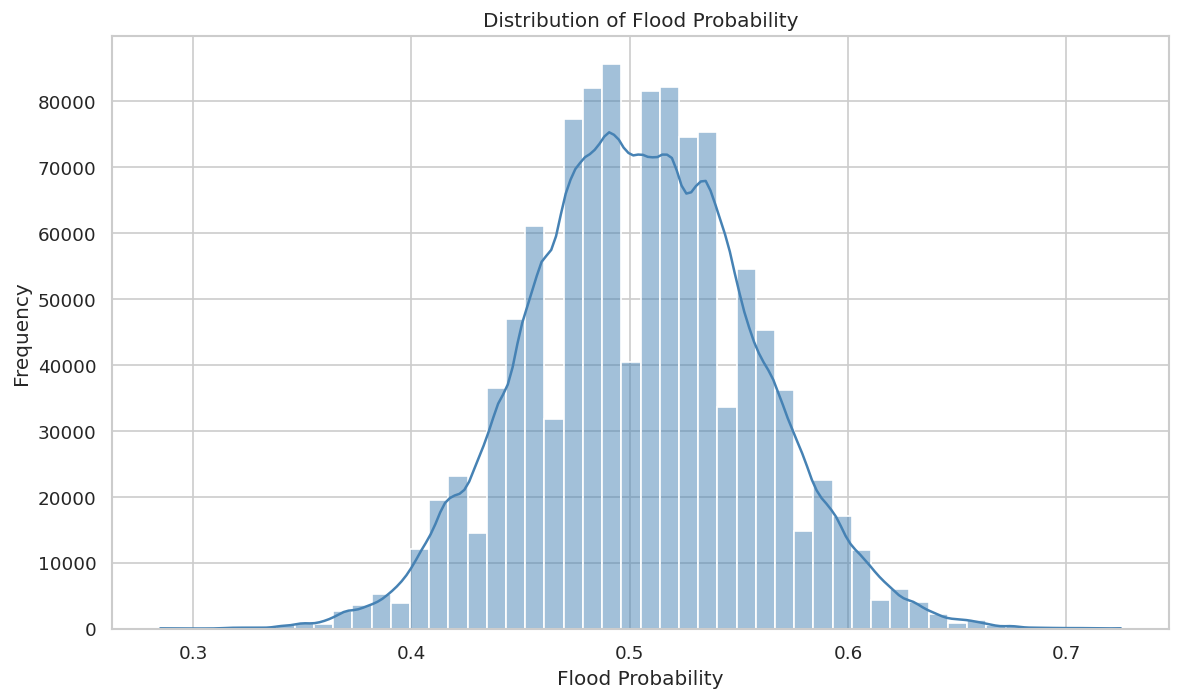

In [6]:

# ========================================
# 6. Target Variable Distribution
# ========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="FloodProbability",
    bins=50,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Flood Probability")
plt.xlabel("Flood Probability")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


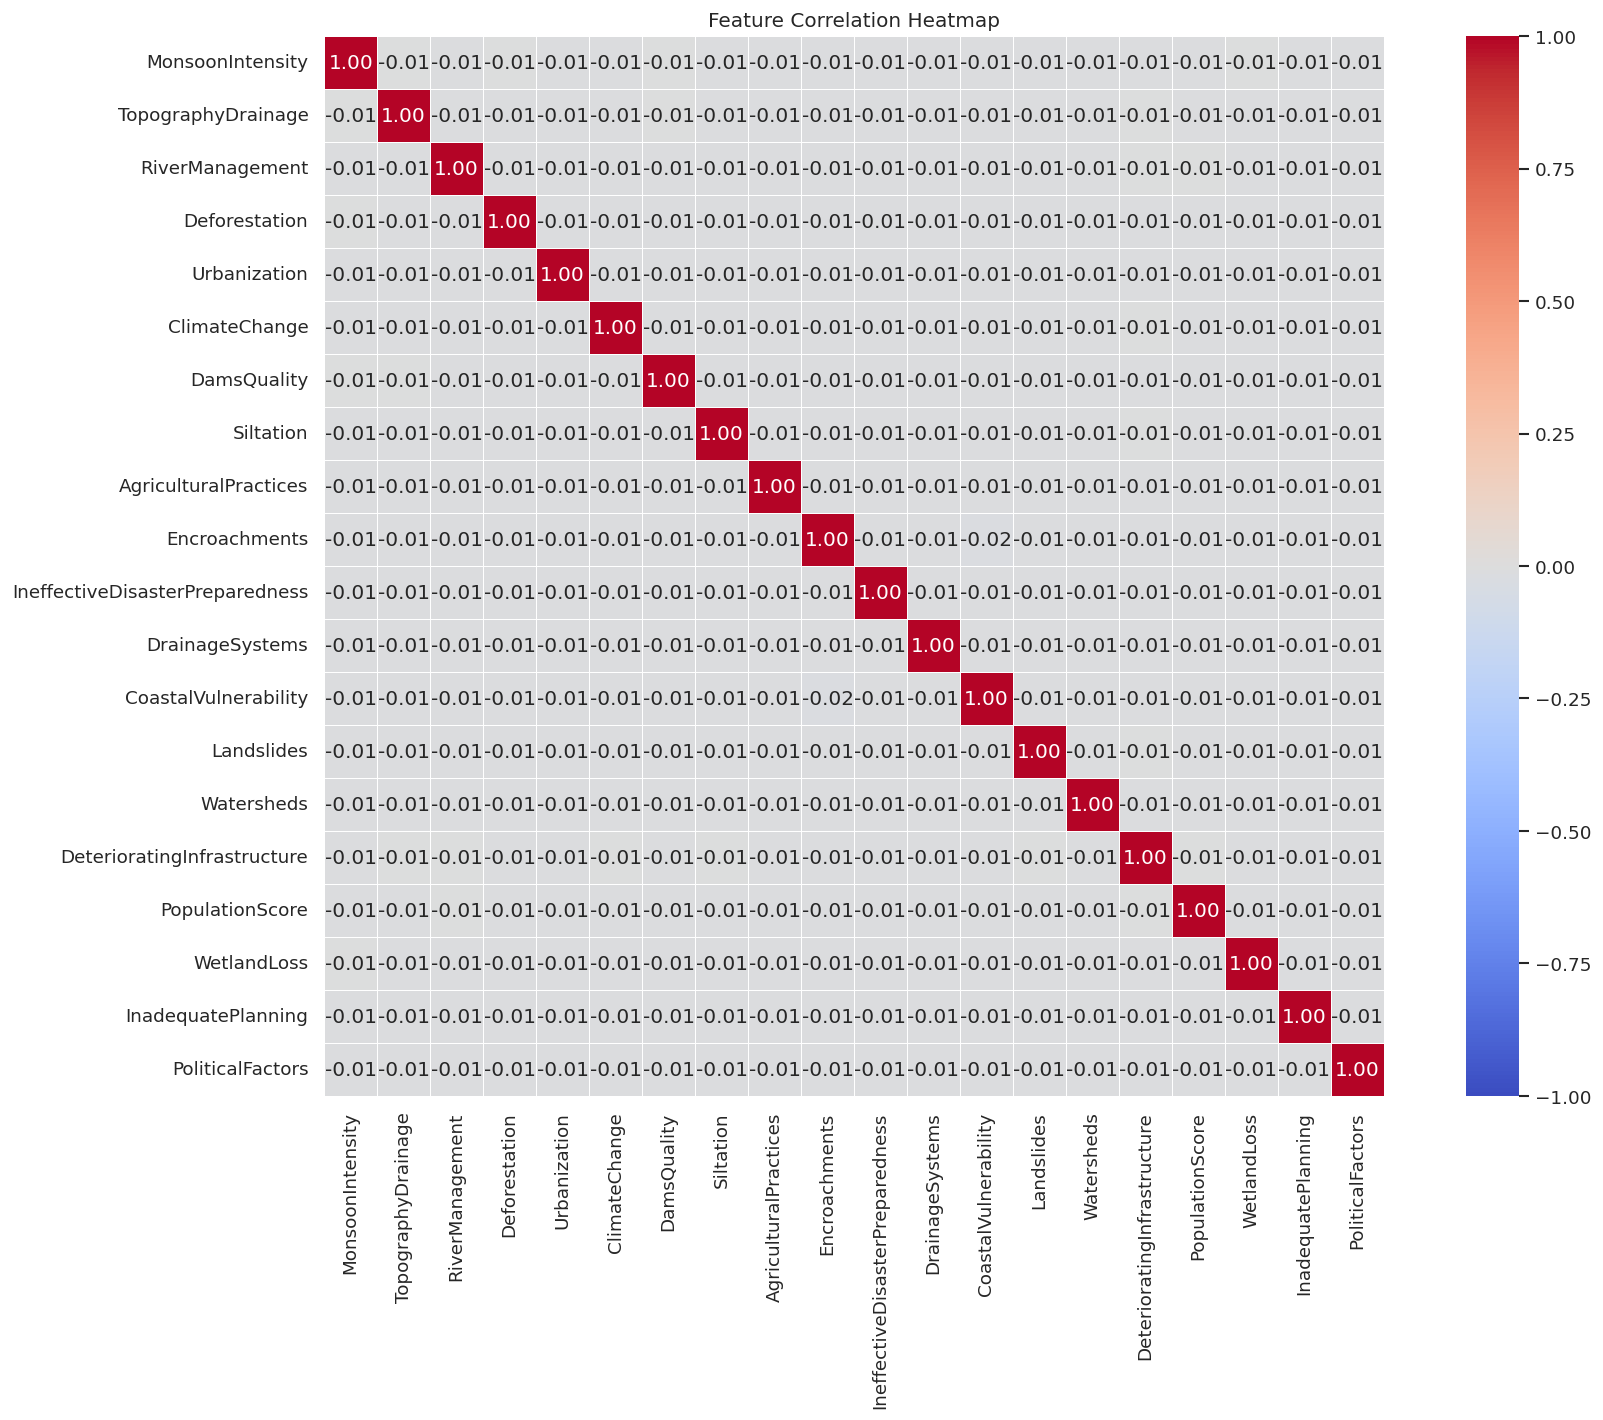

In [7]:

# ========================================
# 7. Feature Correlation Heatmap
# ========================================

# 計算 20 個特徵的 Pearson 相關係數
corr_matrix = X.corr(method="pearson")

# 繪製相關係數熱力圖
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Feature Correlation Heatmap")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


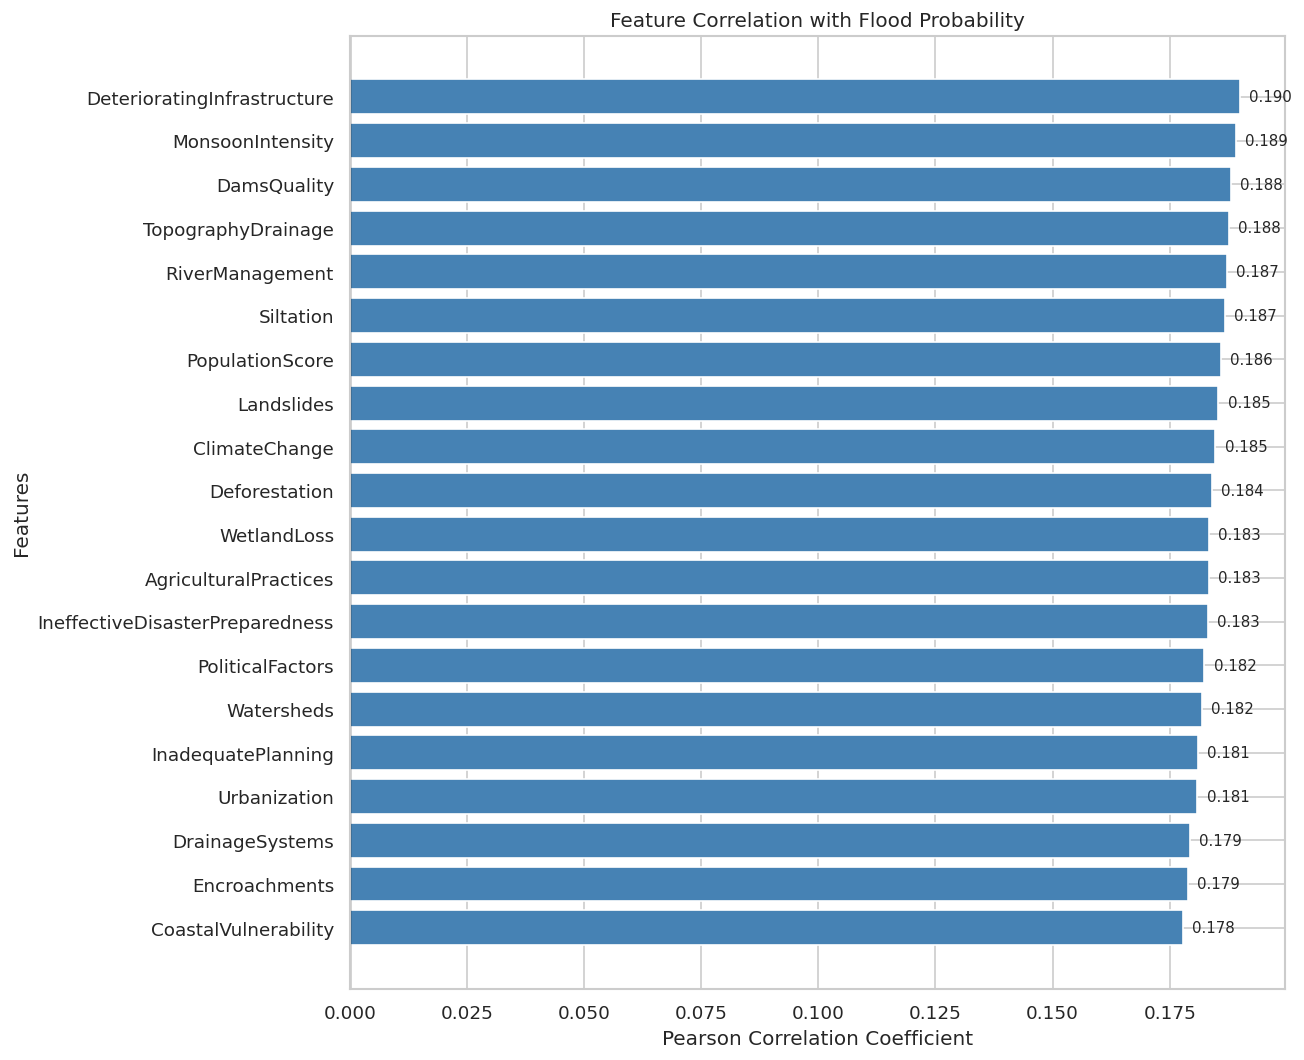

Feature-Target Correlation:


,Correlation
DeterioratingInfrastructure,0.190007
MonsoonIntensity,0.189098
DamsQuality,0.187996
TopographyDrainage,0.187635
RiverManagement,0.187131
Siltation,0.186789
PopulationScore,0.185890
Landslides,0.185346
ClimateChange,0.184761
Deforestation,0.184001


In [8]:

# ========================================
# 8. Feature-Target Correlation
# ========================================

# 計算每個特徵與目標變數的 Pearson 相關係數
target_corr = (
    df[feature_cols + [target]]
    .corr(method="pearson")[target]
    .drop(target)
    .sort_values(ascending=False)
)

# 依正負相關設定顏色
colors = [
    "steelblue" if value >= 0 else "salmon"
    for value in target_corr.values
]

# 繪製水平長條圖
plt.figure(figsize=(11, 9))

plt.barh(
    target_corr.index,
    target_corr.values,
    color=colors
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("Feature Correlation with Flood Probability")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")

# 顯示數值標籤
for i, value in enumerate(target_corr.values):
    offset = 0.002 if value >= 0 else -0.002
    plt.text(
        value + offset,
        i,
        f"{value:.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 顯示完整相關係數表
print("Feature-Target Correlation:")
display(target_corr.to_frame(name="Correlation"))


**Data Understanding 小結**

- `train.csv` 共 1,117,957 筆、22 欄（`id` + 20 個 int64 特徵 + 目標 `FloodProbability`），沒有缺失值，排除 `id` 後也沒有重複資料。
- 目標變數平均約 0.504、標準差約 0.051，範圍 0.285～0.725，集中在 0.5 附近。
- 特徵之間的相關係數都接近 0，初步看不出多重共線性；每個特徵和目標的相關係數都只有約 0.18～0.19，**單一特徵的解釋力很弱**，預測訊號分散在 20 個特徵中。

# 3. Data Preparation（資料準備）

In [9]:

# ========================================
# CRISP-DM: Data Preparation
# 9. Data Cleaning
# ========================================

# 建立副本，保留原始資料
df_clean = df.copy()

# 刪除 id 欄位
df_clean = df_clean.drop(
    columns=["id"],
    errors="ignore"
)

# 檢查缺失值
print("Missing Values Before Processing:")
print(df_clean.isnull().sum())

# 檢查重複資料
duplicates = df_clean.duplicated().sum()
print("\nDuplicated Rows:", duplicates)

# 刪除完全重複的資料列
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("\nDataset Shape After Cleaning:", df_clean.shape)

# 定義目標與特徵
target = "FloodProbability"

# 若目標變數缺失，該筆資料無法用於監督式學習
df_clean = df_clean.dropna(subset=[target])

X = df_clean.drop(columns=[target])
y = df_clean[target]

print("Number of Features:", X.shape[1])
print("Remaining Missing Values in Features:",
      X.isnull().sum().sum())


Missing Values Before Processing:
MonsoonIntensity                   0
TopographyDrainage                 0
RiverManagement                    0
Deforestation                      0
Urbanization                       0
ClimateChange                      0
DamsQuality                        0
Siltation                          0
AgriculturalPractices              0
Encroachments                      0
IneffectiveDisasterPreparedness    0
DrainageSystems                    0
CoastalVulnerability               0
Landslides                         0
Watersheds                         0
DeterioratingInfrastructure        0
PopulationScore                    0
WetlandLoss                        0
InadequatePlanning                 0
PoliticalFactors                   0
FloodProbability                   0
dtype: int64

Duplicated Rows: 0

Dataset Shape After Cleaning: (1117957, 21)
Number of Features: 20
Remaining Missing Values in Features: 0


In [10]:

# ========================================
# 10. Train-Test Split
# ========================================

from sklearn.model_selection import train_test_split

# 80% 訓練資料、20% 測試資料
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Set: (894365, 20)
Testing Set: (223592, 20)
Training Target: (894365,)
Testing Target: (223592,)


In [11]:

# ========================================
# 11. Missing Value Imputation
# ========================================

from sklearn.impute import SimpleImputer

# 使用中位數填補數值特徵缺失值
imputer = SimpleImputer(strategy="median")

# 只能使用訓練集計算中位數
X_train_imputed = imputer.fit_transform(X_train)

# 測試集使用相同的填補規則
X_test_imputed = imputer.transform(X_test)

# 轉回 DataFrame，保留欄位名稱
X_train_imputed = pd.DataFrame(
    X_train_imputed,
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

# 確認缺失值已處理
print("Training Missing Values:",
      X_train_imputed.isnull().sum().sum())

print("Testing Missing Values:",
      X_test_imputed.isnull().sum().sum())


Training Missing Values: 0
Testing Missing Values: 0


In [12]:

# ========================================
# 12. Feature Standardization
# ========================================

from sklearn.preprocessing import StandardScaler

# 建立標準化工具
scaler = StandardScaler()

# 使用訓練集計算平均數與標準差
X_train_scaled = scaler.fit_transform(X_train_imputed)

# 測試集套用相同的標準化參數
X_test_scaled = scaler.transform(X_test_imputed)

# 轉為 DataFrame
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# 顯示標準化後的資料
print("Standardized Training Data:")
display(X_train_scaled.head())

# 檢查訓練集各欄位的平均值與標準差
print("\nMean After Scaling:")
print(X_train_scaled.mean().round(4))

print("\nStandard Deviation After Scaling:")
print(X_train_scaled.std(ddof=0).round(4))


Standardized Training Data:


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,IneffectiveDisasterPreparedness,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors
805665,1.496677,0.990017,0.986031,0.516689,-0.451461,-0.939865,3.862973,1.487635,-0.940384,-1.416252,0.026269,0.508498,0.499886,0.513869,0.033418,0.035455,-1.410998,0.508182,-0.452211,0.987014
863045,1.010640,-0.443144,-0.461872,-1.434464,-0.451461,0.032383,0.981810,-0.932379,0.511087,-1.416252,-1.417811,0.508498,0.021176,-2.373132,0.513439,-1.417736,0.034495,-0.459044,-0.932863,-0.448558
496045,0.524603,0.034576,-1.909775,0.516689,0.509078,1.004630,-0.938965,0.035626,0.511087,-0.456529,-0.455091,0.025747,0.978597,0.513869,0.033418,-0.448942,1.961819,-0.942657,0.028442,-0.927083
1079364,-0.447470,0.512297,0.503396,-0.946676,-0.931730,-0.939865,-1.899352,0.035626,-0.456560,0.503195,0.988988,1.956750,0.499886,-1.410798,0.033418,-0.448942,0.998157,0.991795,-0.452211,-1.884131
191800,0.524603,-0.920865,1.468665,-1.434464,0.989347,-0.453741,0.501617,0.519629,0.994911,0.503195,-0.936451,0.025747,-1.414955,0.513869,0.513439,0.035455,0.034495,-0.459044,-0.452211,2.422586



Mean After Scaling:
MonsoonIntensity                   0.0
TopographyDrainage                -0.0
RiverManagement                    0.0
Deforestation                     -0.0
Urbanization                      -0.0
ClimateChange                     -0.0
DamsQuality                        0.0
Siltation                         -0.0
AgriculturalPractices             -0.0
Encroachments                     -0.0
IneffectiveDisasterPreparedness    0.0
DrainageSystems                   -0.0
CoastalVulnerability              -0.0
Landslides                        -0.0
Watersheds                         0.0
DeterioratingInfrastructure       -0.0
PopulationScore                    0.0
WetlandLoss                       -0.0
InadequatePlanning                 0.0
PoliticalFactors                   0.0
dtype: float64

Standard Deviation After Scaling:
MonsoonIntensity                   1.0
TopographyDrainage                 1.0
RiverManagement                    1.0
Deforestation                   

In [13]:

# ========================================
# 13. Final Data Verification
# ========================================

print("=== Data Preparation Summary ===")

print("Training Features:", X_train_scaled.shape)
print("Testing Features:", X_test_scaled.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# 驗證特徵數量
assert X_train_scaled.shape[1] == 20

# 驗證缺失值
assert not X_train_scaled.isnull().any().any()
assert not X_test_scaled.isnull().any().any()

# 驗證資料沒有無限值
assert np.isfinite(X_train_scaled.to_numpy()).all()
assert np.isfinite(X_test_scaled.to_numpy()).all()

print("\nData Preparation Completed Successfully!")


=== Data Preparation Summary ===
Training Features: (894365, 20)
Testing Features: (223592, 20)
Training Target: (894365,)
Testing Target: (223592,)

Data Preparation Completed Successfully!


**Data Preparation 小結**

刪除 `id`、檢查重複值與目標缺失 → 80% / 20% 切分（`random_state=42`）→ 以訓練集中位數填補缺失值 → `StandardScaler` 只用訓練集 fit。所有需要學習統計量的步驟都只用訓練資料，避免測試集資訊洩漏；特徵選擇階段更進一步在每個 CV fold 內重新 fit。

# 4. Modeling（建模）

## 4.1 Feature Selection（特徵選擇）

比較三種方法，只使用訓練資料，以 5-fold 交叉驗證的平均 R² 評估：

1. **SelectKBest（f_regression）**：依單變量 F 檢定分數挑前 k 名（Filter 法）
2. **RFE（LinearRegression）**：反覆刪除係數最小的特徵（Wrapper 法）
3. **LassoCV**：L1 正則化，依係數絕對值排序取前 k 名（Embedded 法）

k = 5、10、15、20。填補與標準化都放在每個 fold 的訓練資料內執行。

In [14]:

# ========================================
# CRISP-DM: Feature Selection
# 14. Import Libraries and Settings
# ========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

# 實驗設定
k_values = [5, 10, 15, 20]
methods = ["SelectKBest", "RFE", "LassoCV"]

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 使用未標準化的訓練集
# 標準化會在每個 CV fold 內重新執行
X_fs = X_train.copy()
y_fs = y_train.copy()

assert X_fs.shape[1] == 20
assert X_fs.columns.is_unique
assert y_fs.notna().all()

feature_names = X_fs.columns.to_numpy()

# LassoCV 的 Alpha 搜尋範圍
lasso_alphas = np.logspace(-5, -0.5, 40)

print("Feature Selection Settings")
print("Methods:", methods)
print("Feature Counts:", k_values)
print("CV Folds:", cv.get_n_splits())
print("Training Samples:", len(X_fs))


Feature Selection Settings
Methods: ['SelectKBest', 'RFE', 'LassoCV']
Feature Counts: [5, 10, 15, 20]
CV Folds: 5
Training Samples: 894365


In [15]:

# ========================================
# 15. Feature Selection Functions
# ========================================

def select_features(method, k, X_data, y_data, lasso_model=None):
    """
    根據指定方法選擇 k 個特徵
    回傳：選取欄位的 Boolean mask
    """

    if method == "SelectKBest":

        selector = SelectKBest(
            score_func=f_regression,
            k=k
        )
        selector.fit(X_data, y_data)
        return selector.get_support()

    elif method == "RFE":

        selector = RFE(
            estimator=LinearRegression(),
            n_features_to_select=k,
            step=1
        )
        selector.fit(X_data, y_data)
        return selector.get_support()

    elif method == "LassoCV":

        # LassoCV 先選最佳 Alpha
        # 再依係數絕對值排序取前 k 名
        if lasso_model is None:
            raise ValueError("Lasso model is required")

        importance = np.abs(lasso_model.coef_)

        # 相同係數以原始欄位順序決定排序
        ranking = np.argsort(-importance, kind="stable")

        selected = ranking[:k]

        mask = np.zeros(
            X_data.shape[1],
            dtype=bool
        )
        mask[selected] = True

        return mask

    else:
        raise ValueError("Unknown method")


In [16]:

# ========================================
# 16. Five-Fold Cross-Validation
# ========================================

results = []

# 儲存每個方法及 k 的五折 R²
cv_scores = {
    (method, k): []
    for method in methods
    for k in k_values
}

# 外層 5-Fold Cross-Validation
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_fs), start=1
):

    print(f"Processing Fold {fold}/5")

    X_tr = X_fs.iloc[train_idx]
    X_val = X_fs.iloc[val_idx]

    y_tr = y_fs.iloc[train_idx]
    y_val = y_fs.iloc[val_idx]

    # 只使用該折訓練資料計算填補值
    imputer_fold = SimpleImputer(strategy="median")

    X_tr_imp = imputer_fold.fit_transform(X_tr)
    X_val_imp = imputer_fold.transform(X_val)

    # 只使用該折訓練資料計算標準化參數
    scaler_fold = StandardScaler()

    X_tr_s = scaler_fold.fit_transform(X_tr_imp)
    X_val_s = scaler_fold.transform(X_val_imp)

    # LassoCV 每折只訓練一次，減少運算量
    # 內層 3-fold 用來選擇正則化強度
    lasso = LassoCV(
        alphas=lasso_alphas,
        cv=3,
        max_iter=4000,
        n_jobs=-1,
        random_state=42
    )

    lasso.fit(X_tr_s, y_tr)

    # 評估三種方法
    for method in methods:

        for k in k_values:

            mask = select_features(
                method,
                k,
                X_tr_s,
                y_tr,
                lasso_model=lasso
            )

            # 使用選取的 k 個特徵
            X_tr_selected = X_tr_s[:, mask]
            X_val_selected = X_val_s[:, mask]

            # 以相同的 LinearRegression 評估
            model = LinearRegression()

            model.fit(X_tr_selected, y_tr)

            y_pred = model.predict(X_val_selected)

            score = r2_score(y_val, y_pred)

            cv_scores[(method, k)].append(score)

# 整理每組實驗結果
for method in methods:
    for k in k_values:

        scores = np.array(cv_scores[(method, k)])

        results.append({
            "Method": method,
            "K": k,
            "Mean R2": scores.mean(),
            "Std R2": scores.std(ddof=1),
            "SE R2": scores.std(ddof=1) / np.sqrt(5)
        })

results_df = pd.DataFrame(results)

print("\nCross-Validation Results:")
display(results_df.round(6))


Processing Fold 1/5
Processing Fold 2/5
Processing Fold 3/5
Processing Fold 4/5
Processing Fold 5/5

Cross-Validation Results:


,Method,K,Mean R2,Std R2,SE R2
0,SelectKBest,5,0.182628,0.001963,0.000878
1,SelectKBest,10,0.378713,0.001338,0.000599
2,SelectKBest,15,0.595836,0.000465,0.000208
3,SelectKBest,20,0.844959,0.000559,0.000250
4,RFE,5,0.181119,0.001688,0.000755
5,RFE,10,0.377274,0.001445,0.000646
6,RFE,15,0.596608,0.000892,0.000399
7,RFE,20,0.844959,0.000559,0.000250
8,LassoCV,5,0.175896,0.001908,0.000853
9,LassoCV,10,0.374414,0.002452,0.001097


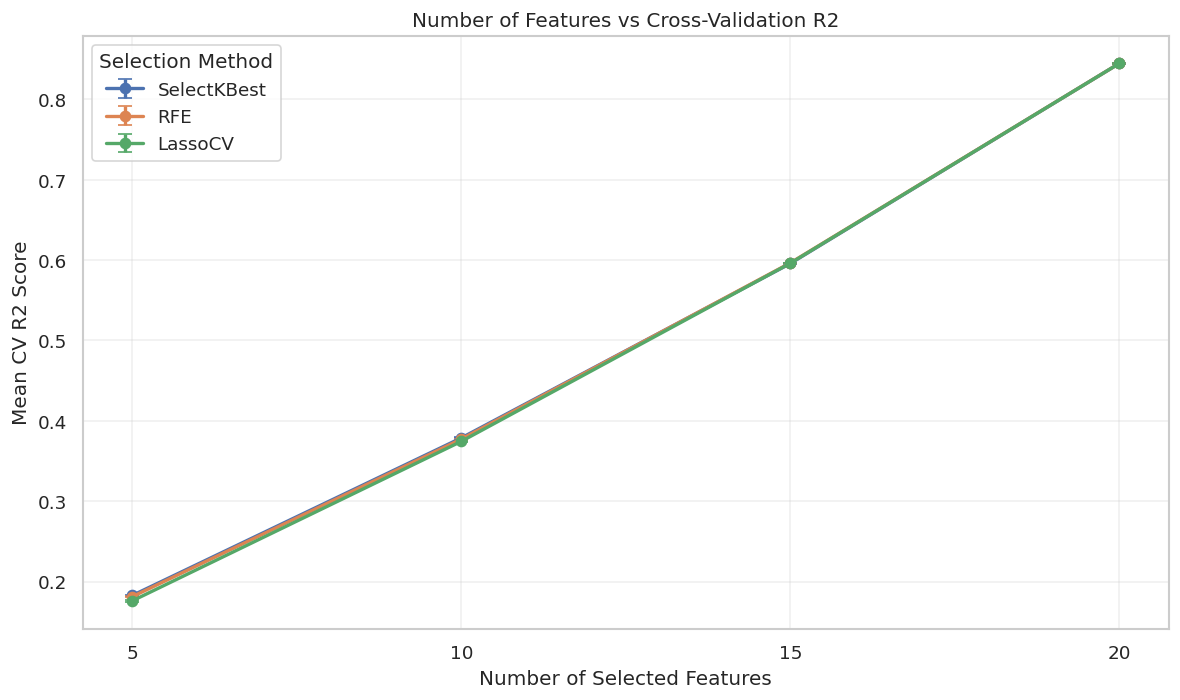

In [17]:

# ========================================
# 17. Feature Count vs R2
# ========================================

plt.figure(figsize=(10, 6))

for method in methods:

    subset = results_df[
        results_df["Method"] == method
    ].sort_values("K")

    plt.errorbar(
        subset["K"],
        subset["Mean R2"],
        yerr=subset["SE R2"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method
    )

plt.title("Number of Features vs Cross-Validation R2")
plt.xlabel("Number of Selected Features")
plt.ylabel("Mean CV R2 Score")
plt.xticks(k_values)

plt.legend(title="Selection Method")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


In [18]:

# ========================================
# 18. R2 Comparison Table
# ========================================

# 將比較結果整理成矩陣
comparison_table = results_df.pivot(
    index="K",
    columns="Method",
    values="Mean R2"
)

print("Mean Cross-Validation R2:")
display(comparison_table.round(6))

# 顯示完整排名
ranking_df = results_df.sort_values(
    by="Mean R2",
    ascending=False
).reset_index(drop=True)

print("\nModel Ranking:")
display(ranking_df.round(6))


Mean Cross-Validation R2:


Method,LassoCV,RFE,SelectKBest
K,,,
5,0.175896,0.181119,0.182628
10,0.374414,0.377274,0.378713
15,0.596223,0.596608,0.595836
20,0.844959,0.844959,0.844959



Model Ranking:


,Method,K,Mean R2,Std R2,SE R2
0,SelectKBest,20,0.844959,0.000559,0.000250
1,RFE,20,0.844959,0.000559,0.000250
2,LassoCV,20,0.844959,0.000559,0.000250
3,RFE,15,0.596608,0.000892,0.000399
4,LassoCV,15,0.596223,0.000674,0.000301
5,SelectKBest,15,0.595836,0.000465,0.000208
6,SelectKBest,10,0.378713,0.001338,0.000599
7,RFE,10,0.377274,0.001445,0.000646
8,LassoCV,10,0.374414,0.002452,0.001097
9,SelectKBest,5,0.182628,0.001963,0.000878


In [19]:

# ========================================
# 19. Final Feature Selection
# ========================================

# 只使用完整訓練集 fit 前處理
final_imputer = SimpleImputer(strategy="median")
X_train_imp = final_imputer.fit_transform(X_fs)

final_scaler = StandardScaler()
X_train_s = final_scaler.fit_transform(X_train_imp)

# 用完整訓練集建立 LassoCV
final_lasso = LassoCV(
    alphas=lasso_alphas,
    cv=5,
    max_iter=4000,
    n_jobs=-1,
    random_state=42
)

final_lasso.fit(X_train_s, y_fs)

# 儲存每組方法選到的特徵
feature_results = []
selected_features_dict = {}

for method in methods:
    for k in k_values:

        mask = select_features(
            method,
            k,
            X_train_s,
            y_fs,
            lasso_model=final_lasso
        )

        selected_names = feature_names[mask].tolist()

        selected_features_dict[(method, k)] = selected_names

        feature_results.append({
            "Method": method,
            "K": k,
            "Selected Features": ", ".join(selected_names)
        })

feature_table = pd.DataFrame(feature_results)

print("Selected Features by Method:")
display(feature_table)


Selected Features by Method:


,Method,K,Selected Features
0,SelectKBest,5,"MonsoonIntensity, TopographyDrainage, DamsQual..."
1,SelectKBest,10,"MonsoonIntensity, TopographyDrainage, RiverMan..."
2,SelectKBest,15,"MonsoonIntensity, TopographyDrainage, RiverMan..."
3,SelectKBest,20,"MonsoonIntensity, TopographyDrainage, RiverMan..."
4,RFE,5,"TopographyDrainage, RiverManagement, DamsQuali..."
5,RFE,10,"TopographyDrainage, RiverManagement, DamsQuali..."
6,RFE,15,"TopographyDrainage, RiverManagement, Deforesta..."
7,RFE,20,"MonsoonIntensity, TopographyDrainage, RiverMan..."
8,LassoCV,5,"TopographyDrainage, Urbanization, CoastalVulne..."
9,LassoCV,10,"TopographyDrainage, RiverManagement, Urbanizat..."


Best Lasso Alpha: 1e-05
Nonzero Coefficients: 20
Zero Coefficients: 0


,Feature,Coefficient,Nonzero,Abs Coefficient
12,CoastalVulnerability,0.011834,True,0.011834
1,TopographyDrainage,0.011804,True,0.011804
19,PoliticalFactors,0.011785,True,0.011785
16,PopulationScore,0.011779,True,0.011779
4,Urbanization,0.011771,True,0.011771
6,DamsQuality,0.011760,True,0.011760
14,Watersheds,0.011753,True,0.011753
9,Encroachments,0.011753,True,0.011753
2,RiverManagement,0.011720,True,0.011720
13,Landslides,0.011716,True,0.011716


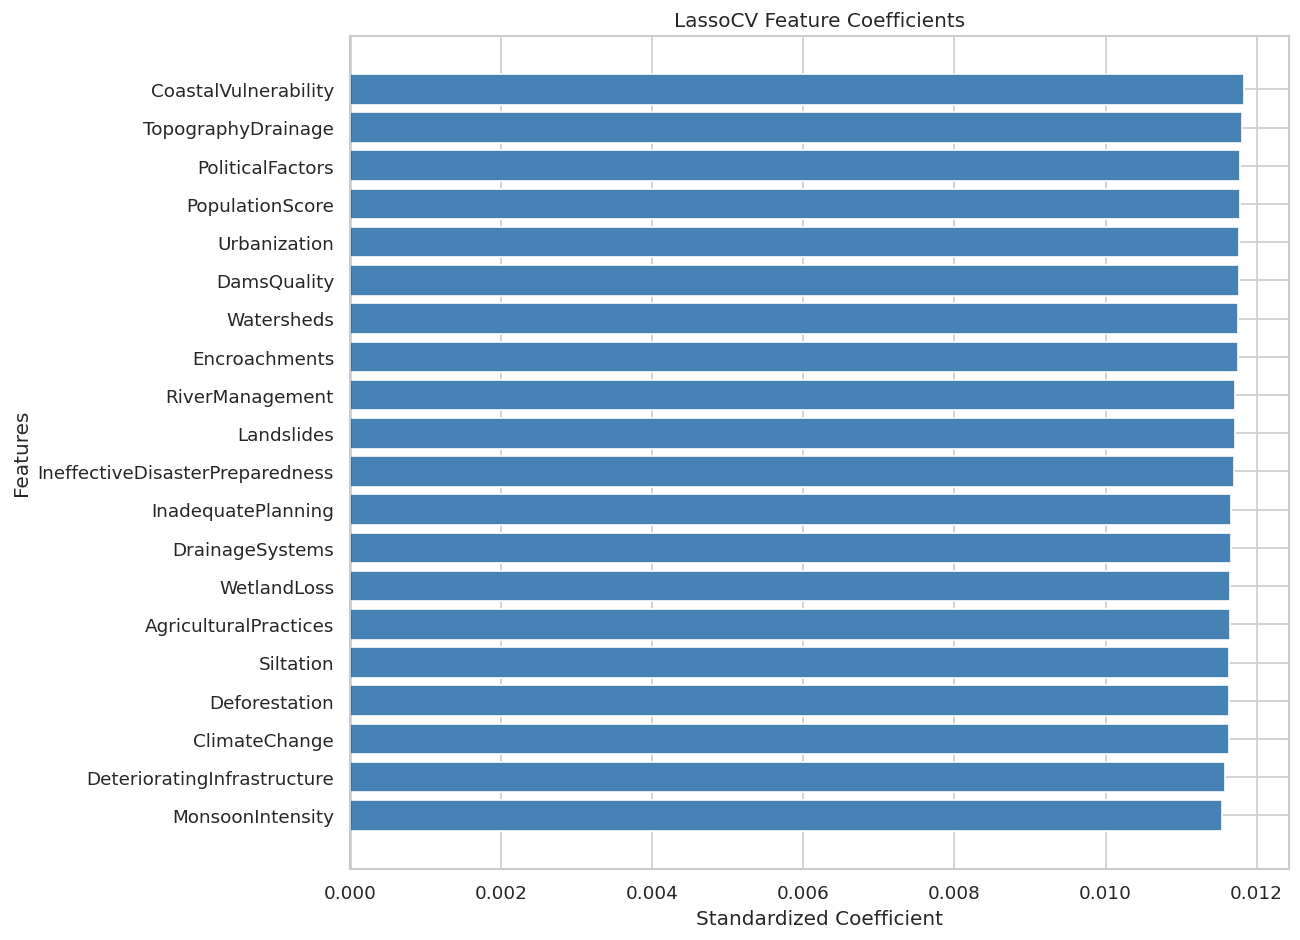

In [20]:

# ========================================
# 20. LassoCV Coefficient Analysis
# ========================================

# 建立係數表
lasso_coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": final_lasso.coef_
})

# 標記非零係數
# atol 用來處理浮點運算中的極小數值
lasso_coef_df["Nonzero"] = ~np.isclose(
    lasso_coef_df["Coefficient"],
    0,
    atol=1e-8,
    rtol=0
)

# 依絕對係數大小排序
lasso_coef_df["Abs Coefficient"] = (
    lasso_coef_df["Coefficient"].abs()
)

lasso_coef_df = lasso_coef_df.sort_values(
    "Abs Coefficient",
    ascending=False
)

print("Best Lasso Alpha:", final_lasso.alpha_)

print("Nonzero Coefficients:",
      lasso_coef_df["Nonzero"].sum())

print("Zero Coefficients:",
      (~lasso_coef_df["Nonzero"]).sum())

display(lasso_coef_df.round(6))

# 係數長條圖
plt.figure(figsize=(11, 8))

colors = [
    "steelblue" if value else "salmon"
    for value in lasso_coef_df["Nonzero"]
]

plt.barh(
    lasso_coef_df["Feature"],
    lasso_coef_df["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()

plt.title("LassoCV Feature Coefficients")
plt.xlabel("Standardized Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


In [21]:

# ========================================
# 21. Model Recommendation
# ========================================

# 取得平均 R2 最高的組合
best_row = results_df.loc[
    results_df["Mean R2"].idxmax()
]

# 最佳模型的 1-SE 門檻
threshold = best_row["Mean R2"] - best_row["SE R2"]

# 篩選落在 1-SE 範圍內的候選組合
candidates = results_df[
    results_df["Mean R2"] >= threshold
].copy()

# 優先選較少特徵，同數量時選較高 R2
recommended = candidates.sort_values(
    by=["K", "Mean R2"],
    ascending=[True, False]
).iloc[0]

best_method = recommended["Method"]
best_k = int(recommended["K"])

best_features = selected_features_dict[
    (best_method, best_k)
]

print("=== Highest Mean R2 ===")
print("Method:", best_row["Method"])
print("K:", int(best_row["K"]))
print("Mean R2:", round(best_row["Mean R2"], 6))

print("\n=== Recommended Feature Set ===")
print("Method:", best_method)
print("K:", best_k)
print("Mean R2:", round(recommended["Mean R2"], 6))

print("\nSelected Features:")
for i, feature in enumerate(best_features, 1):
    print(f"{i}. {feature}")

print("\nRecommendation Reason:")
print(
    "Selected the smallest feature set within "
    "one standard error of the best mean CV R2."
)


=== Highest Mean R2 ===
Method: SelectKBest
K: 20
Mean R2: 0.844959

=== Recommended Feature Set ===
Method: SelectKBest
K: 20
Mean R2: 0.844959

Selected Features:
1. MonsoonIntensity
2. TopographyDrainage
3. RiverManagement
4. Deforestation
5. Urbanization
6. ClimateChange
7. DamsQuality
8. Siltation
9. AgriculturalPractices
10. Encroachments
11. IneffectiveDisasterPreparedness
12. DrainageSystems
13. CoastalVulnerability
14. Landslides
15. Watersheds
16. DeterioratingInfrastructure
17. PopulationScore
18. WetlandLoss
19. InadequatePlanning
20. PoliticalFactors

Recommendation Reason:
Selected the smallest feature set within one standard error of the best mean CV R2.


**特徵選擇結論**

- 三種方法結果幾乎相同：k = 5、10、15 時 CV R² 約為 0.18、0.38、0.60，**k = 20 才達到 0.845**。
- R² 隨特徵數近似線性上升，代表每個特徵貢獻的訊號差不多，刪掉任何特徵都會損失預測力。
- LassoCV 選出的最佳 alpha 很小（1e-5），20 個係數都沒有被壓成 0，同樣支持保留全部特徵。
- 依 **1-SE 規則**（在最佳 R² 一個標準誤以內選最少特徵），推薦的組合仍是 **20 個特徵**，最終模型採用全部 20 個特徵。

## 4.2 Modeling（多元線性回歸模型建立）

以選出的特徵建立 LinearRegression、Ridge（RidgeCV）、Lasso（LassoCV），並使用 statsmodels OLS 取得係數、p-value、R² 與 Adjusted R²。

In [22]:

# ========================================
# CRISP-DM: Modeling
# 22. Prepare Selected Features
# ========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (
    LinearRegression, RidgeCV, LassoCV
)
from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 使用前一階段選出的最佳特徵
selected_features = list(best_features)

# 檢查特徵數量
assert len(selected_features) > 0
assert len(selected_features) == len(set(selected_features))
assert set(selected_features).issubset(X_train.columns)
assert set(selected_features).issubset(X_test.columns)

# 選取相同特徵
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

print("Selected Features:", len(selected_features))
print("Feature Names:", selected_features)

print("Training Shape:", X_train_selected.shape)
print("Testing Shape:", X_test_selected.shape)


Selected Features: 20
Feature Names: ['MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors']
Training Shape: (894365, 20)
Testing Shape: (223592, 20)


In [23]:

# ========================================
# 23. Train Regression Models
# ========================================

# 5-Fold CV 設定
inner_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 正則化強度搜尋範圍
alphas = np.logspace(-5, 2, 40)

# 建立三種回歸模型
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": RidgeCV(
        alphas=alphas,
        cv=inner_cv,
        scoring="r2"
    ),
    "Lasso": LassoCV(
        alphas=alphas,
        cv=inner_cv,
        max_iter=10000,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
predictions = []
results = []

for name, estimator in models.items():

    # 前處理與模型整合
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    # 只使用訓練資料 fit
    pipeline.fit(X_train_selected, y_train)

    # 預測測試資料
    y_pred = pipeline.predict(X_test_selected)

    trained_models[name] = pipeline
    predictions.append((name, y_pred))

    # 評估指標
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 取得最佳 Alpha
    alpha = getattr(
        pipeline.named_steps["model"],
        "alpha_",
        np.nan
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Alpha": alpha
    })

# 顯示模型比較表
results_df_model = pd.DataFrame(results)

print("Model Comparison (Test Set):")
display(results_df_model.round(6))


Model Comparison (Test Set):


,Model,MAE,MSE,RMSE,R2,Alpha
0,LinearRegression,0.015792,0.000403,0.02008,0.844877,NaN
1,Ridge,0.015792,0.000403,0.02008,0.844877,3.665241
2,Lasso,0.015796,0.000403,0.02008,0.844877,0.000010


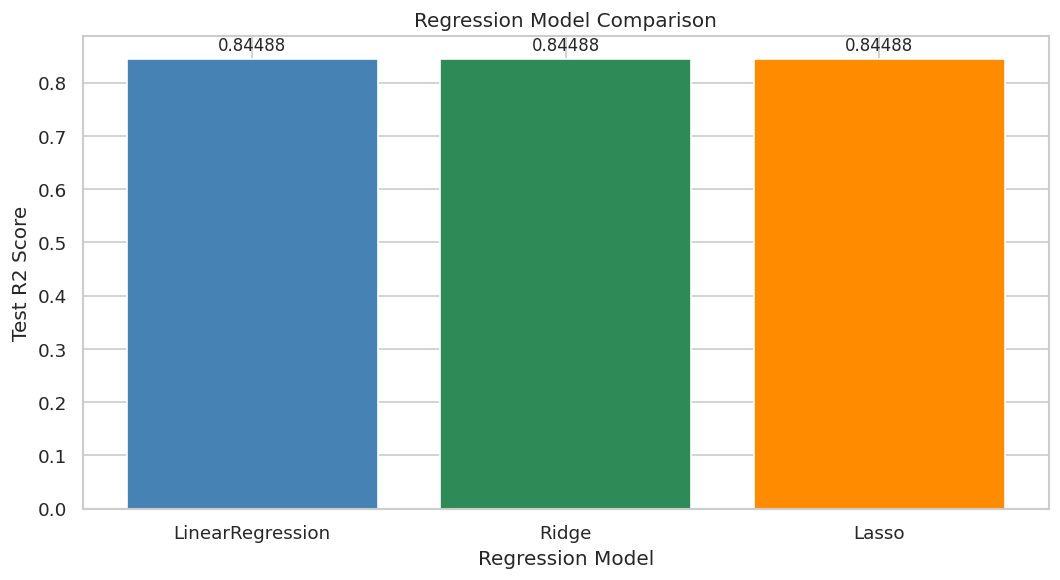

In [24]:

# ========================================
# 24. Model Performance Comparison
# ========================================

plt.figure(figsize=(9, 5))

bars = plt.bar(
    results_df_model["Model"],
    results_df_model["R2"],
    color=["steelblue", "seagreen", "darkorange"]
)

plt.title("Regression Model Comparison")
plt.xlabel("Regression Model")
plt.ylabel("Test R2 Score")
plt.axhline(0, color="black", linewidth=0.8)

for bar in bars:
    value = bar.get_height()
    plt.annotate(
        f"{value:.5f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5 if value >= 0 else -12),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()


In [25]:

# ========================================
# 25. Statsmodels OLS Regression
# ========================================

# 取得 LinearRegression 的前處理工具
linear_pipeline = trained_models["LinearRegression"]

imputer = linear_pipeline.named_steps["imputer"]
scaler = linear_pipeline.named_steps["scaler"]

# 使用已由訓練集 fit 的前處理工具
X_train_ols = scaler.transform(
    imputer.transform(X_train_selected)
)

X_test_ols = scaler.transform(
    imputer.transform(X_test_selected)
)

# 轉成 DataFrame，保留特徵名稱
X_train_ols = pd.DataFrame(
    X_train_ols,
    columns=selected_features,
    index=X_train_selected.index
)

X_test_ols = pd.DataFrame(
    X_test_ols,
    columns=selected_features,
    index=X_test_selected.index
)

# 加入截距項
X_train_ols = sm.add_constant(
    X_train_ols,
    has_constant="add"
)

X_test_ols = sm.add_constant(
    X_test_ols,
    has_constant="add"
)

# 建立 OLS 模型
ols_model = sm.OLS(
    y_train,
    X_train_ols
).fit()

# 印出完整統計結果
print(ols_model.summary())

# 測試集預測
y_pred_ols = ols_model.predict(X_test_ols)

print("\nOLS Test R2:",
      round(r2_score(y_test, y_pred_ols), 6))

# 比較 sklearn 與 statsmodels 預測
linear_pred = linear_pipeline.predict(X_test_selected)

print("Maximum Prediction Difference:",
      np.max(np.abs(linear_pred - y_pred_ols)))


                            OLS Regression Results                            
Dep. Variable:       FloodProbability   R-squared:                       0.845
Model:                            OLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                 2.437e+05
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:18:23   Log-Likelihood:             2.2255e+06
No. Observations:              894365   AIC:                        -4.451e+06
Df Residuals:                  894344   BIC:                        -4.451e+06
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

Top 5 Features:


,Feature,Coefficient,P-value,Abs Coefficient
CoastalVulnerability,CoastalVulnerability,0.011847,0.0,0.011847
TopographyDrainage,TopographyDrainage,0.011817,0.0,0.011817
PoliticalFactors,PoliticalFactors,0.011798,0.0,0.011798
PopulationScore,PopulationScore,0.011791,0.0,0.011791
Urbanization,Urbanization,0.011784,0.0,0.011784


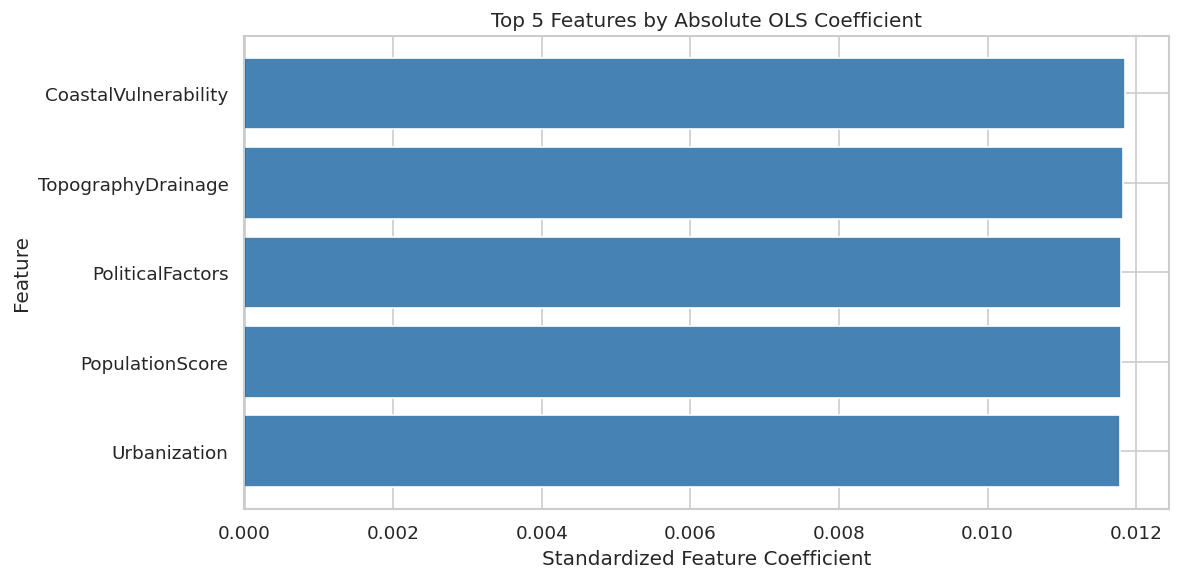

In [26]:

# ========================================
# 26. Top 5 Important Features
# ========================================

coef_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": ols_model.params.drop("const"),
    "P-value": ols_model.pvalues.drop("const")
})

coef_df["Abs Coefficient"] = (
    coef_df["Coefficient"].abs()
)

# 依標準化係數絕對值排序
coef_df = coef_df.sort_values(
    "Abs Coefficient",
    ascending=False
)

top5 = coef_df.head(5)

print("Top 5 Features:")
display(top5.round(6))

# 視覺化係數
plt.figure(figsize=(10, 5))

colors = [
    "steelblue" if c >= 0 else "salmon"
    for c in top5["Coefficient"]
]

plt.barh(
    top5["Feature"],
    top5["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()

plt.title("Top 5 Features by Absolute OLS Coefficient")
plt.xlabel("Standardized Feature Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [27]:

# ========================================
# 27. Interpret Top 5 Coefficients
# ========================================

print("=== Top 5 Feature Interpretation ===\n")

for rank, (feature, row) in enumerate(
    top5.iterrows(), start=1
):

    coef = row["Coefficient"]
    p_value = row["P-value"]

    direction = "增加" if coef > 0 else "減少"

    print(f"{rank}. {feature}")
    print(f"   Coefficient: {coef:.6f}")
    print(f"   P-value: {p_value:.6g}")

    print(
        f"   在其他變數固定下，"
        f"{feature} 增加 1 個原始標準差時，"
        f"模型預測的 FloodProbability "
        f"{direction} {abs(coef):.6f}。"
    )

    if p_value < 0.05:
        print("   Nominal p-value < 0.05")
    else:
        print("   Nominal p-value >= 0.05")

    print()


=== Top 5 Feature Interpretation ===

1. CoastalVulnerability
   Coefficient: 0.011847
   P-value: 0
   在其他變數固定下，CoastalVulnerability 增加 1 個原始標準差時，模型預測的 FloodProbability 增加 0.011847。
   Nominal p-value < 0.05

2. TopographyDrainage
   Coefficient: 0.011817
   P-value: 0
   在其他變數固定下，TopographyDrainage 增加 1 個原始標準差時，模型預測的 FloodProbability 增加 0.011817。
   Nominal p-value < 0.05

3. PoliticalFactors
   Coefficient: 0.011798
   P-value: 0
   在其他變數固定下，PoliticalFactors 增加 1 個原始標準差時，模型預測的 FloodProbability 增加 0.011798。
   Nominal p-value < 0.05

4. PopulationScore
   Coefficient: 0.011791
   P-value: 0
   在其他變數固定下，PopulationScore 增加 1 個原始標準差時，模型預測的 FloodProbability 增加 0.011791。
   Nominal p-value < 0.05

5. Urbanization
   Coefficient: 0.011784
   P-value: 0
   在其他變數固定下，Urbanization 增加 1 個原始標準差時，模型預測的 FloodProbability 增加 0.011784。
   Nominal p-value < 0.05



In [28]:

# ========================================
# 28. Modeling Summary
# ========================================

best_model_row = results_df_model.loc[
    results_df_model["R2"].idxmax()
]

print("=== Final Modeling Results ===")

print("Selected Features:", len(selected_features))

print("\nBest Predictive Model:")
print(best_model_row["Model"])

print("Test R2:", round(best_model_row["R2"], 6))
print("Test RMSE:", round(best_model_row["RMSE"], 6))
print("Test MAE:", round(best_model_row["MAE"], 6))

print("\nOLS Statistical Summary:")
print("Training R2:", round(ols_model.rsquared, 6))
print("Adjusted R2:", round(ols_model.rsquared_adj, 6))
print("Test R2:", round(r2_score(y_test, y_pred_ols), 6))

print("\nTop 5 Features:")
for feature in top5["Feature"]:
    print("-", feature)


=== Final Modeling Results ===
Selected Features: 20

Best Predictive Model:
Ridge
Test R2: 0.844877
Test RMSE: 0.02008
Test MAE: 0.015792

OLS Statistical Summary:
Training R2: 0.844968
Adjusted R2: 0.844964
Test R2: 0.844877

Top 5 Features:
- CoastalVulnerability
- TopographyDrainage
- PoliticalFactors
- PopulationScore
- Urbanization


**Modeling 小結**

- 三個模型的測試 R² 都約為 0.8449，RMSE 約 0.0201，正則化（Ridge/Lasso）幾乎沒有帶來改善，表示模型沒有過度擬合。
- OLS 訓練集 R² = 0.845、Adjusted R² = 0.845，所有係數 p-value < 0.05。
- 20 個標準化係數都是正值，而且大小非常接近（約 0.0115～0.0118）：每個風險因子增加 1 個標準差，預測洪水機率約增加 0.012。這代表目標值近似「20 個特徵的加權總和」，下面 5.6 節的特徵加總實驗會驗證這一點。

# 5. Evaluation（模型評估）

在獨立的測試集上計算 MAE、MSE、RMSE、R²、Adjusted R²；畫出實際值 vs 預測值、**95% 信賴區間與預測區間**，並以殘差圖、Q-Q Plot、VIF 檢查線性回歸假設。為了加快繪圖，散佈圖只抽樣 5,000 筆，區間圖抽樣 100 筆。

In [29]:

# ========================================
# CRISP-DM: Evaluation
# 29. Libraries and Settings
# ========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from IPython.display import display
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# 圖表設定
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# 抽樣數量
PLOT_SAMPLE = 5000
INTERVAL_SAMPLE = 100
RANDOM_STATE = 42

# 確認前一階段模型已存在
assert len(selected_features) > 0
assert all(
    name in trained_models
    for name in ["LinearRegression", "Ridge", "Lasso"]
)

print("Evaluation setup completed.")


Evaluation setup completed.


## 5.1 測試集評估指標

In [30]:

# ========================================
# 30. Model Evaluation Table
# ========================================

# 測試集實際值
y_true = np.asarray(y_test, dtype=float)

# 測試集樣本數
n = len(y_true)

# 使用相同數量的輸入特徵
p = len(selected_features)

assert n > p + 1

# 儲存各模型的預測
eval_predictions = {}

for name, model in trained_models.items():
    eval_predictions[name] = np.asarray(
        model.predict(X_test_selected),
        dtype=float
    )

# OLS 使用前面 Cell 25 建立的模型與設計矩陣
eval_predictions["OLS"] = np.asarray(
    ols_model.predict(X_test_ols),
    dtype=float
)

evaluation_results = []

for name, y_pred in eval_predictions.items():

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    # 以測試集 R2 計算 Adjusted R2
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Adjusted R2": adj_r2
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    "R2", ascending=False
).reset_index(drop=True)

print("=== Test Set Evaluation ===")
display(evaluation_df.round(6))

print("\nBest Model:")
print(evaluation_df.iloc[0]["Model"])


=== Test Set Evaluation ===


,Model,MAE,MSE,RMSE,R2,Adjusted R2
0,Ridge,0.015792,0.000403,0.02008,0.844877,0.844863
1,LinearRegression,0.015792,0.000403,0.02008,0.844877,0.844863
2,OLS,0.015792,0.000403,0.02008,0.844877,0.844863
3,Lasso,0.015796,0.000403,0.02008,0.844877,0.844863



Best Model:
Ridge


## 5.2 實際值 vs 預測值

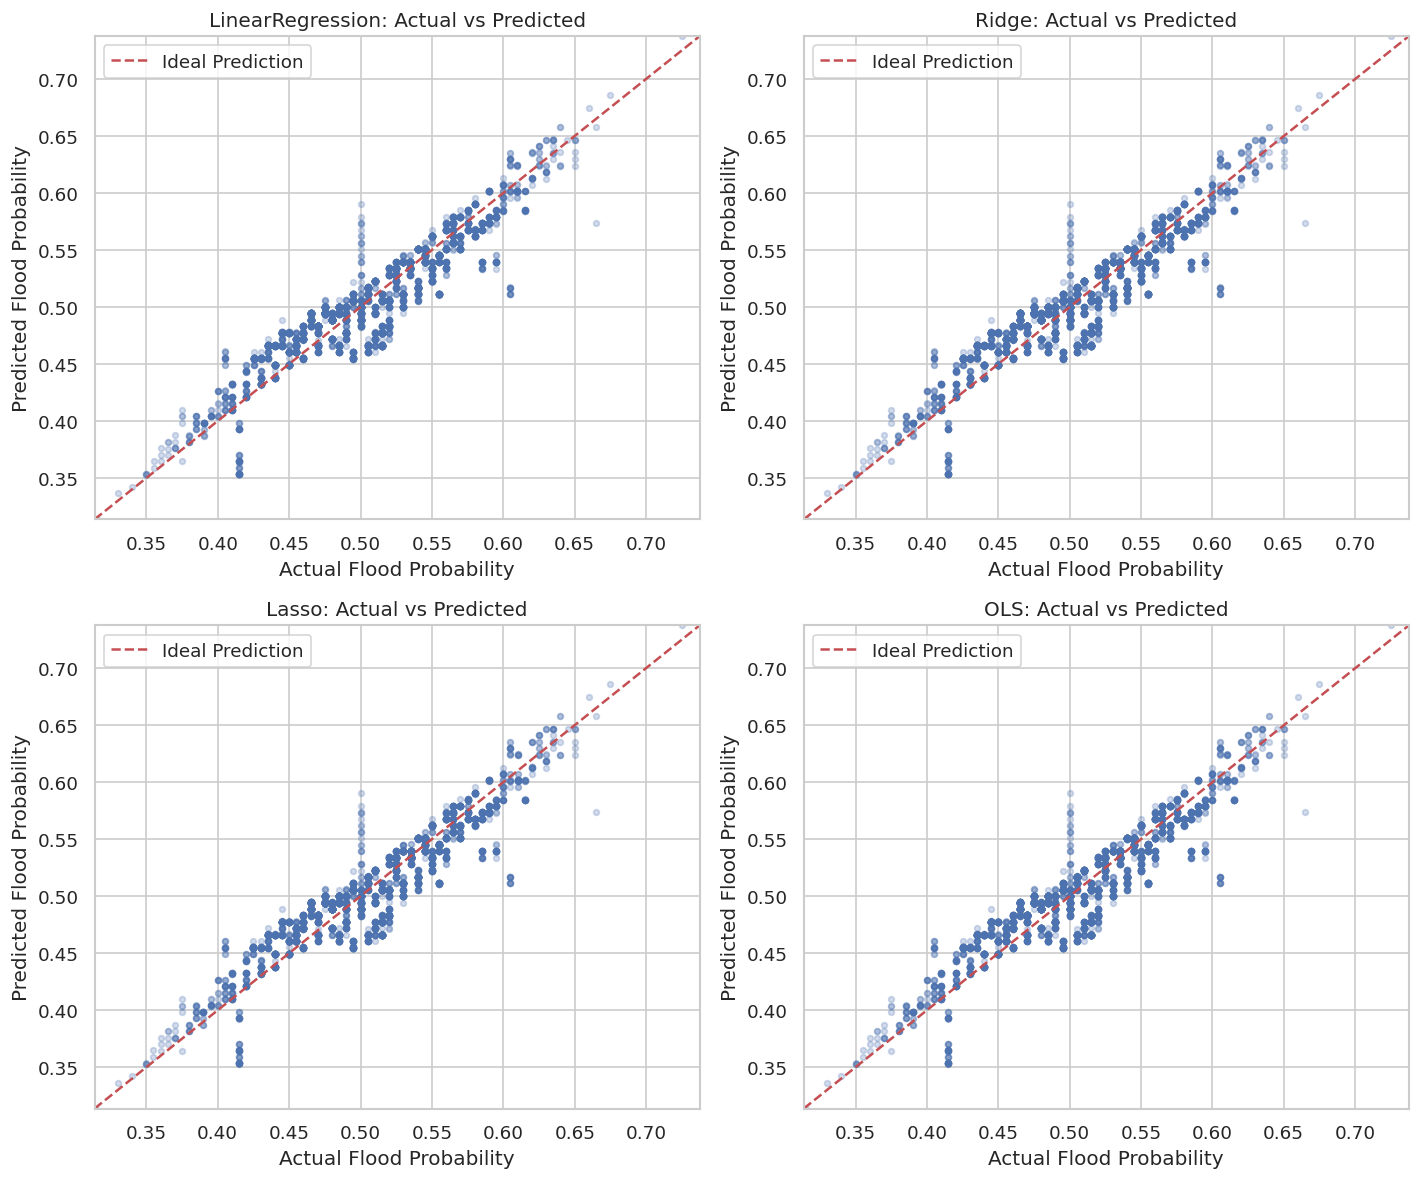

In [31]:

# ========================================
# 31. Actual vs Predicted
# ========================================

rng = np.random.default_rng(RANDOM_STATE)

# 隨機抽樣，不重複
sample_size = min(PLOT_SAMPLE, n)

sample_idx = rng.choice(
    n,
    size=sample_size,
    replace=False
)

fig, axes = plt.subplots(
    2, 2, figsize=(12, 10)
)

for ax, (name, y_pred) in zip(
    axes.flat,
    eval_predictions.items()
):

    actual_sample = y_true[sample_idx]
    predicted_sample = y_pred[sample_idx]

    ax.scatter(
        actual_sample,
        predicted_sample,
        alpha=0.25,
        s=12
    )

    # y=x 參考線
    lower = min(actual_sample.min(), predicted_sample.min())
    upper = max(actual_sample.max(), predicted_sample.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--",
        linewidth=1.5,
        label="Ideal Prediction"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Flood Probability")
    ax.set_ylabel("Predicted Flood Probability")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.legend()

plt.tight_layout()
plt.show()


## 5.3 預測圖：95% 信賴區間（CI）與預測區間（PI）

使用 `ols_model.get_prediction(X).summary_frame(alpha=0.05)`：
- `mean_ci_lower / mean_ci_upper`：**平均預測值**的 95% 信賴區間（較窄）
- `obs_ci_lower / obs_ci_upper`：**單筆新觀測值**的 95% 預測區間（較寬，多包含個別誤差）

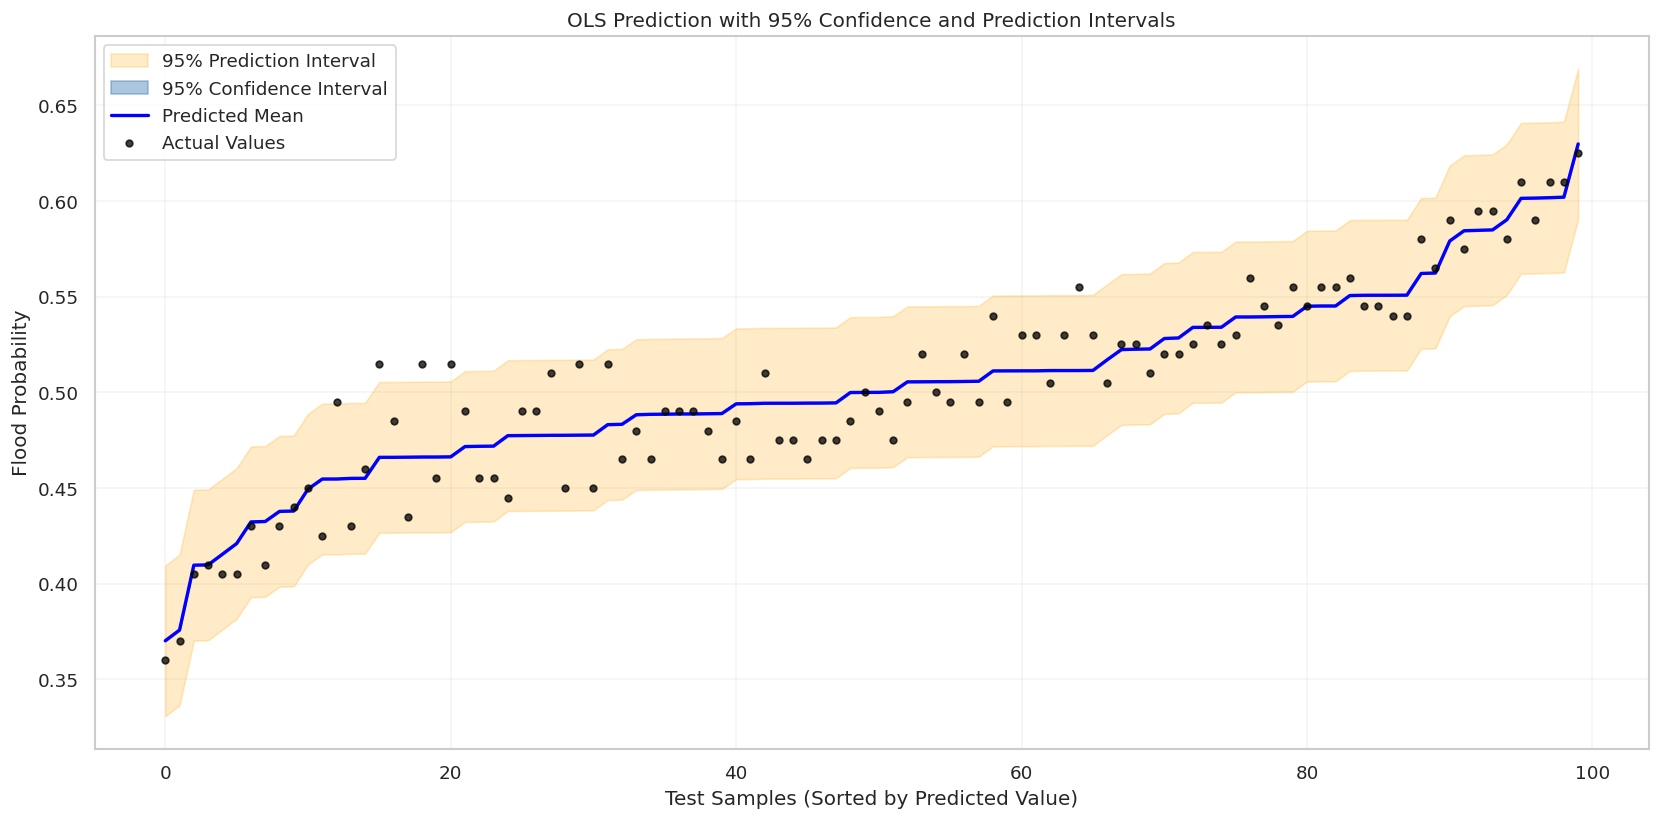

,Actual,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,0.360,0.370155,0.369946,0.370364,0.330768,0.409542
1,0.370,0.375752,0.375550,0.375955,0.336365,0.415139
2,0.405,0.409657,0.409484,0.409830,0.370270,0.449044
3,0.410,0.409823,0.409631,0.410015,0.370436,0.449210
4,0.405,0.415373,0.415151,0.415594,0.375986,0.454760
5,0.405,0.420969,0.420767,0.421172,0.381582,0.460356
6,0.430,0.432261,0.432103,0.432419,0.392874,0.471648
7,0.410,0.432486,0.432323,0.432649,0.393099,0.471873
8,0.430,0.437766,0.437579,0.437954,0.398379,0.477153
9,0.440,0.437976,0.437780,0.438173,0.398589,0.477363


In [32]:

# ========================================
# 32. OLS Confidence and Prediction Intervals
# ========================================

# 隨機抽取最多 100 筆測試資料
rng_interval = np.random.default_rng(RANDOM_STATE)

interval_idx = rng_interval.choice(
    len(y_test),
    size=min(INTERVAL_SAMPLE, len(y_test)),
    replace=False
)

# 以位置索引取得 OLS 設計矩陣
X_interval = X_test_ols.iloc[interval_idx].copy()

# 取得實際目標值
y_interval = np.asarray(
    y_test.iloc[interval_idx],
    dtype=float
)

# 透過 statsmodels 計算預測區間
prediction = ols_model.get_prediction(X_interval)

prediction_frame = prediction.summary_frame(
    alpha=0.05
)

# 加入實際值
interval_df = prediction_frame.reset_index(drop=True).copy()
interval_df["Actual"] = y_interval

# 依預測平均值排序
interval_df = interval_df.sort_values(
    "mean"
).reset_index(drop=True)

# X 軸為排序後的樣本序號
x = np.arange(len(interval_df))

plt.figure(figsize=(14, 7))

# 95% 預測區間 (Prediction Interval)
plt.fill_between(
    x,
    interval_df["obs_ci_lower"].to_numpy(),
    interval_df["obs_ci_upper"].to_numpy(),
    color="orange",
    alpha=0.22,
    label="95% Prediction Interval"
)

# 95% 平均值信賴區間 (Confidence Interval)
plt.fill_between(
    x,
    interval_df["mean_ci_lower"].to_numpy(),
    interval_df["mean_ci_upper"].to_numpy(),
    color="steelblue",
    alpha=0.45,
    label="95% Confidence Interval"
)

# OLS 預測值
plt.plot(
    x,
    interval_df["mean"].to_numpy(),
    color="blue",
    linewidth=2,
    label="Predicted Mean"
)

# 實際觀測值
plt.scatter(
    x,
    interval_df["Actual"].to_numpy(),
    color="black",
    s=16,
    alpha=0.75,
    label="Actual Values",
    zorder=3
)

plt.title("OLS Prediction with 95% Confidence and Prediction Intervals")
plt.xlabel("Test Samples (Sorted by Predicted Value)")
plt.ylabel("Flood Probability")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 顯示區間估計表格
display(
    interval_df[
        [
            "Actual",
            "mean",
            "mean_ci_lower",
            "mean_ci_upper",
            "obs_ci_lower",
            "obs_ci_upper"
        ]
    ].head(10).round(6)
)


In [33]:

# ========================================
# 33. Prediction Interval Coverage
# ========================================

# 判斷實際值是否落在 95% 預測區間
covered = (
    (interval_df["Actual"] >= interval_df["obs_ci_lower"]) &
    (interval_df["Actual"] <= interval_df["obs_ci_upper"])
)

coverage = covered.mean()

print("Number of Samples:", len(interval_df))
print(f"Empirical Prediction Interval Coverage: {coverage:.2%}")
print("Nominal Coverage: 95.00%")


Number of Samples: 100
Empirical Prediction Interval Coverage: 95.00%
Nominal Coverage: 95.00%


**區間圖解讀**：信賴區間非常窄（樣本數大，平均預測估計很穩定）；預測區間約為預測值 ±0.04，抽樣 100 筆中約 95% 的實際值落在預測區間內，與理論的 95% 一致。

## 5.4 殘差分析

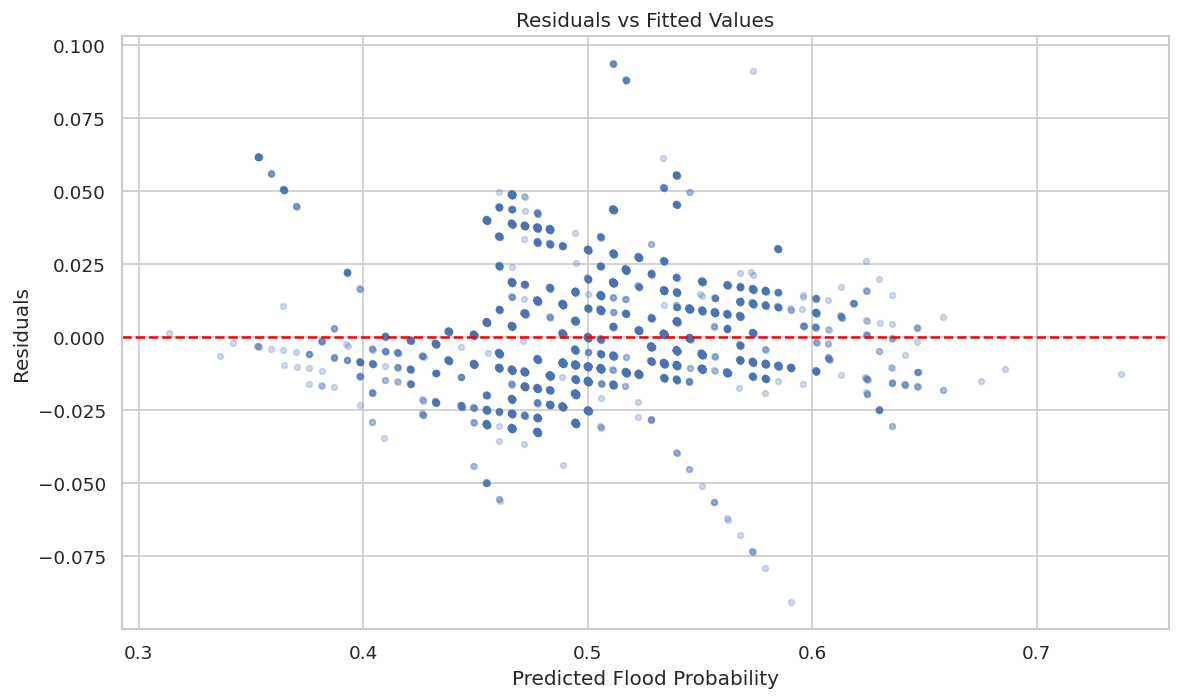

Residual Mean: 2.6e-05
Residual Std: 0.02008


In [34]:

# ========================================
# 34. Residuals vs Fitted Values
# ========================================

# 完整測試集的 OLS 預測與殘差
ols_pred = eval_predictions["OLS"]
residuals = y_true - ols_pred

# 僅抽樣繪圖
pred_sample = ols_pred[sample_idx]
residual_sample = residuals[sample_idx]

plt.figure(figsize=(10, 6))

plt.scatter(
    pred_sample,
    residual_sample,
    alpha=0.25,
    s=12
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

plt.title("Residuals vs Fitted Values")
plt.xlabel("Predicted Flood Probability")
plt.ylabel("Residuals")

plt.tight_layout()
plt.show()

print("Residual Mean:", round(residuals.mean(), 6))
print("Residual Std:", round(residuals.std(), 6))


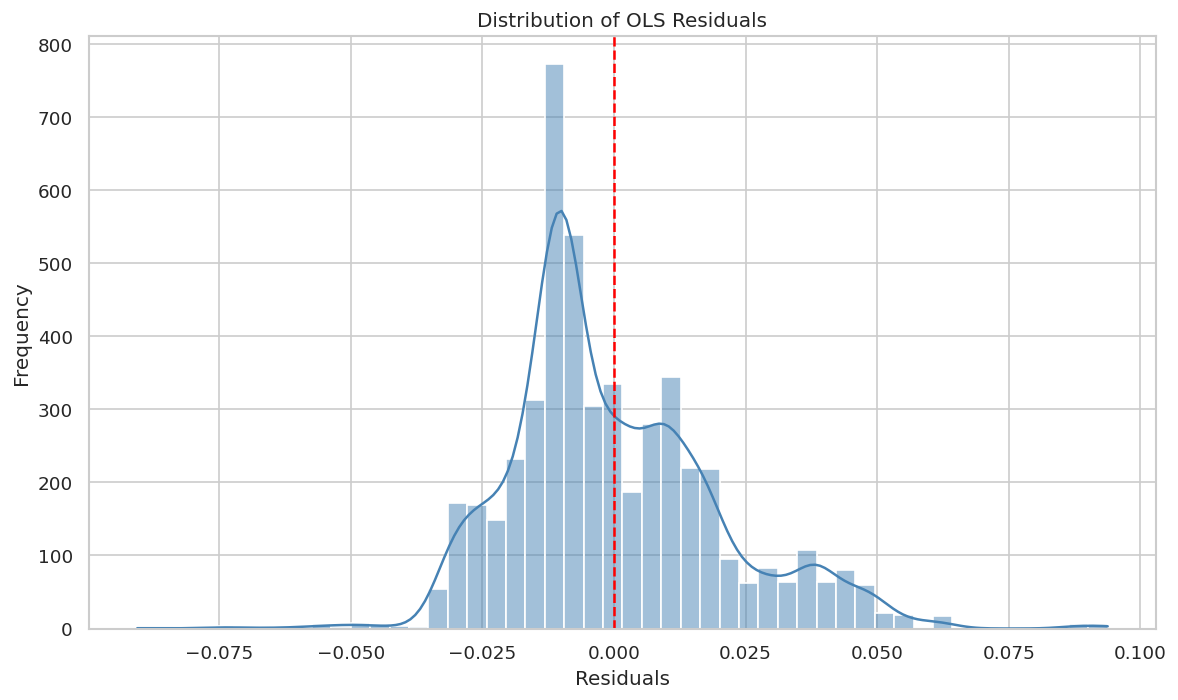

In [35]:

# ========================================
# 35. Residual Distribution
# ========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    residual_sample,
    bins=50,
    kde=True,
    color="steelblue"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Distribution of OLS Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


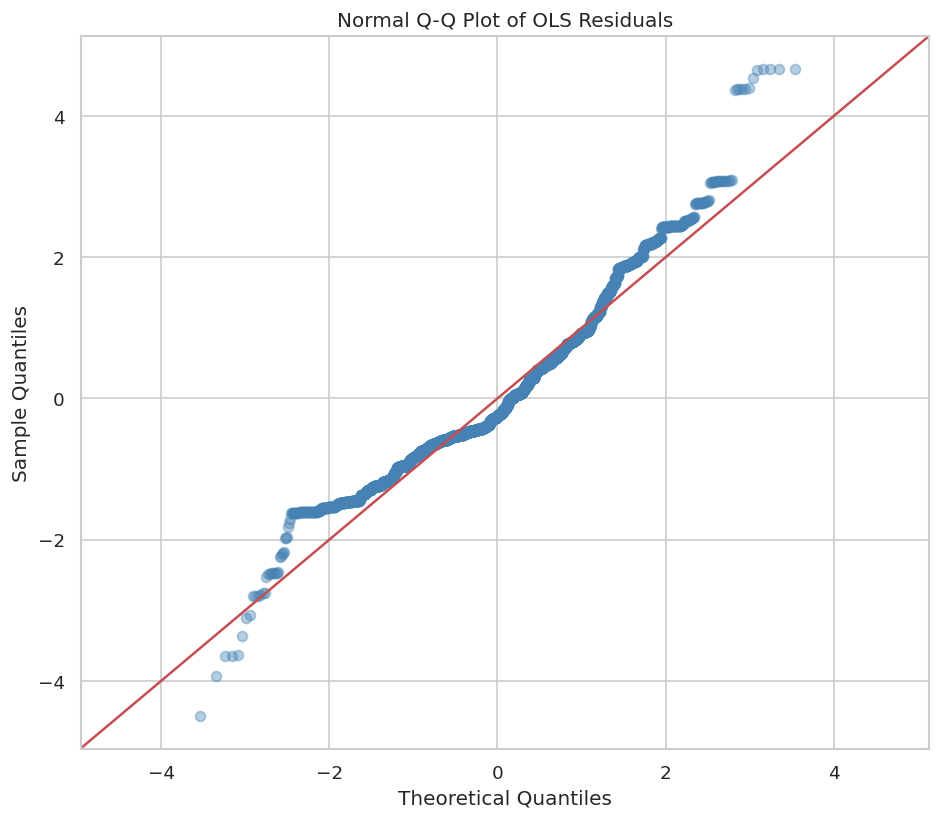

In [36]:

# ========================================
# 36. Normal Q-Q Plot
# ========================================

plt.figure(figsize=(8, 7))

sm.qqplot(
    residual_sample,
    line="45",
    fit=True,
    ax=plt.gca(),
    markerfacecolor="steelblue",
    markeredgecolor="steelblue",
    alpha=0.4
)

plt.title("Normal Q-Q Plot of OLS Residuals")

plt.tight_layout()
plt.show()


## 5.5 多重共線性檢查（VIF）

In [37]:

# ========================================
# 37. Variance Inflation Factor
# ========================================

# 使用前面已標準化的 OLS 訓練資料
# 排除截距 const
X_vif = X_train_ols.drop(
    columns=["const"],
    errors="ignore"
)

# 最多抽取 20,000 筆訓練資料
vif_sample_size = min(20000, len(X_vif))

X_vif_sample = X_vif.sample(
    n=vif_sample_size,
    random_state=42
)

# 計算各特徵的 VIF
vif_results = []

for i, feature in enumerate(X_vif_sample.columns):

    vif = variance_inflation_factor(
        X_vif_sample.to_numpy(),
        i
    )

    vif_results.append({
        "Feature": feature,
        "VIF": vif
    })

vif_df = pd.DataFrame(vif_results)

vif_df = vif_df.sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

print("Variance Inflation Factor:")
display(vif_df.round(4))

print("Maximum VIF:", round(vif_df["VIF"].max(), 4))


Variance Inflation Factor:


,Feature,VIF
0,CoastalVulnerability,1.0058
1,DrainageSystems,1.0051
2,Deforestation,1.0047
3,Watersheds,1.0045
4,InadequatePlanning,1.0045
5,WetlandLoss,1.0043
6,RiverManagement,1.0042
7,Siltation,1.0039
8,Urbanization,1.0038
9,DamsQuality,1.0037


Maximum VIF: 1.0058


,Feature,VIF
0,CoastalVulnerability,1.0058
1,DrainageSystems,1.0051
2,Deforestation,1.0047
3,Watersheds,1.0045
4,InadequatePlanning,1.0045
5,WetlandLoss,1.0043
6,RiverManagement,1.0042
7,Siltation,1.0039
8,Urbanization,1.0038
9,DamsQuality,1.0037


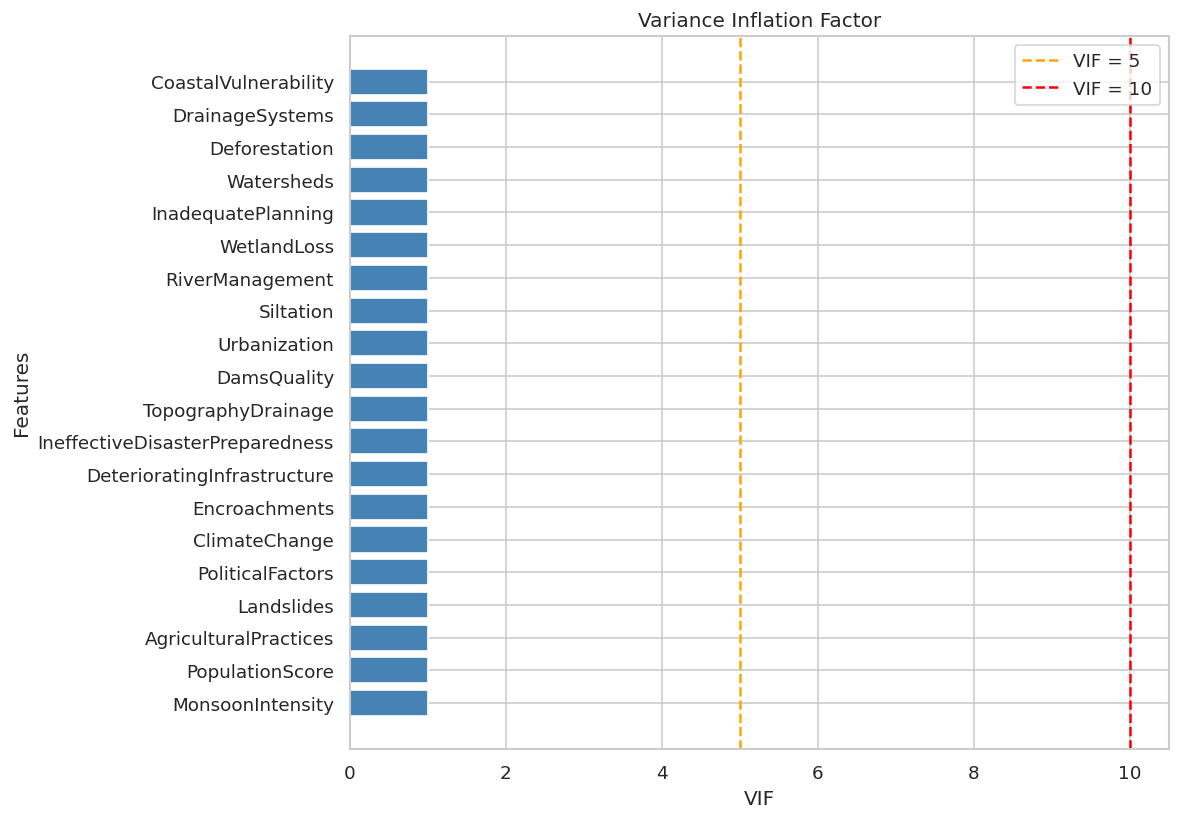

In [38]:

# ========================================
# 38. VIF with Intercept
# ========================================

X_vif_design = sm.add_constant(
    X_vif_sample,
    has_constant="add"
)

vif_results = []

for i, feature in enumerate(X_vif_design.columns):

    if feature == "const":
        continue

    vif = variance_inflation_factor(
        X_vif_design.to_numpy(),
        i
    )

    vif_results.append({
        "Feature": feature,
        "VIF": vif
    })

vif_df = pd.DataFrame(vif_results)

vif_df = vif_df.sort_values(
    "VIF", ascending=False
).reset_index(drop=True)

display(vif_df.round(4))

# VIF 視覺化
plt.figure(figsize=(10, 7))

plt.barh(
    vif_df["Feature"],
    vif_df["VIF"],
    color="steelblue"
)

plt.axvline(
    5,
    color="orange",
    linestyle="--",
    label="VIF = 5"
)

plt.axvline(
    10,
    color="red",
    linestyle="--",
    label="VIF = 10"
)

plt.gca().invert_yaxis()

plt.title("Variance Inflation Factor")
plt.xlabel("VIF")
plt.ylabel("Features")
plt.legend()

plt.tight_layout()
plt.show()


In [39]:

# ========================================
# 39. Regression Diagnostics Summary
# ========================================

from scipy.stats import skew, kurtosis

print("=== Regression Diagnostics ===")

print("\nModel Performance:")
ols_row = evaluation_df[
    evaluation_df["Model"] == "OLS"
].iloc[0]

print("Test R2:", round(ols_row["R2"], 6))
print("Test RMSE:", round(ols_row["RMSE"], 6))

print("\nResidual Statistics:")
print("Mean:", round(residuals.mean(), 6))
print("Standard Deviation:", round(residuals.std(), 6))
print("Skewness:", round(skew(residuals), 6))
print("Excess Kurtosis:", round(kurtosis(residuals), 6))

print("\nMulticollinearity:")
print("Maximum VIF:", round(vif_df["VIF"].max(), 4))
print("Features with VIF > 5:", int((vif_df["VIF"] > 5).sum()))
print("Features with VIF > 10:", int((vif_df["VIF"] > 10).sum()))

print("\nOLS Training Statistics:")
print("R2:", round(ols_model.rsquared, 6))
print("Adjusted R2:", round(ols_model.rsquared_adj, 6))


=== Regression Diagnostics ===

Model Performance:
Test R2: 0.844877
Test RMSE: 0.02008

Residual Statistics:
Mean: 2.6e-05
Standard Deviation: 0.02008
Skewness: 0.694574
Excess Kurtosis: 1.089777

Multicollinearity:
Maximum VIF: 1.0058
Features with VIF > 5: 0
Features with VIF > 10: 0

OLS Training Statistics:
R2: 0.844968
Adjusted R2: 0.844964


**殘差診斷結論**

| 假設 | 檢查方式 | 結果 |
|---|---|---|
| 線性 | 殘差 vs 預測值 | 殘差大致圍繞 0 隨機分布，沒有明顯曲線型態 |
| 殘差平均為 0 | 殘差平均 | 約 2.6e-05，接近 0 |
| 常態性 | 直方圖、Q-Q Plot、偏態/峰度 | 大致鐘形，但偏態約 0.69、超額峰度約 1.09，尾端略偏離常態 |
| 無多重共線性 | VIF | 最大 VIF ≈ 1.006，遠低於 5 / 10 門檻 |

整體而言，模型大致符合線性回歸假設；常態性有輕微偏離，但在百萬筆樣本下對係數估計影響不大。

## 5.6 額外實驗：特徵加總（Feature Engineering）vs 原始 20 特徵

網路高分解法的核心技巧是把 20 個特徵加總成 `feature_sum`。這裡用同一組 80/20 切分比較：

- **A**：只用 1 個特徵 `feature_sum` 的簡單線性回歸
- **B**：使用全部 20 個原始特徵的多元線性回歸

如果 A 和 B 的 R² 幾乎相同，就代表 20 個特徵的資訊幾乎都能濃縮成「總和」，這也解釋了為什麼特徵選擇刪掉任何特徵都會降低 R²。

=== Feature Sum vs All Features (Test Set) ===


,Model,Num Features,MAE,RMSE,R2
0,A: feature_sum only,1,0.015792,0.020081,0.844863
1,B: All 20 features,20,0.015792,0.020080,0.844877


feature_sum coefficient: 0.005646
feature_sum intercept: -0.053311


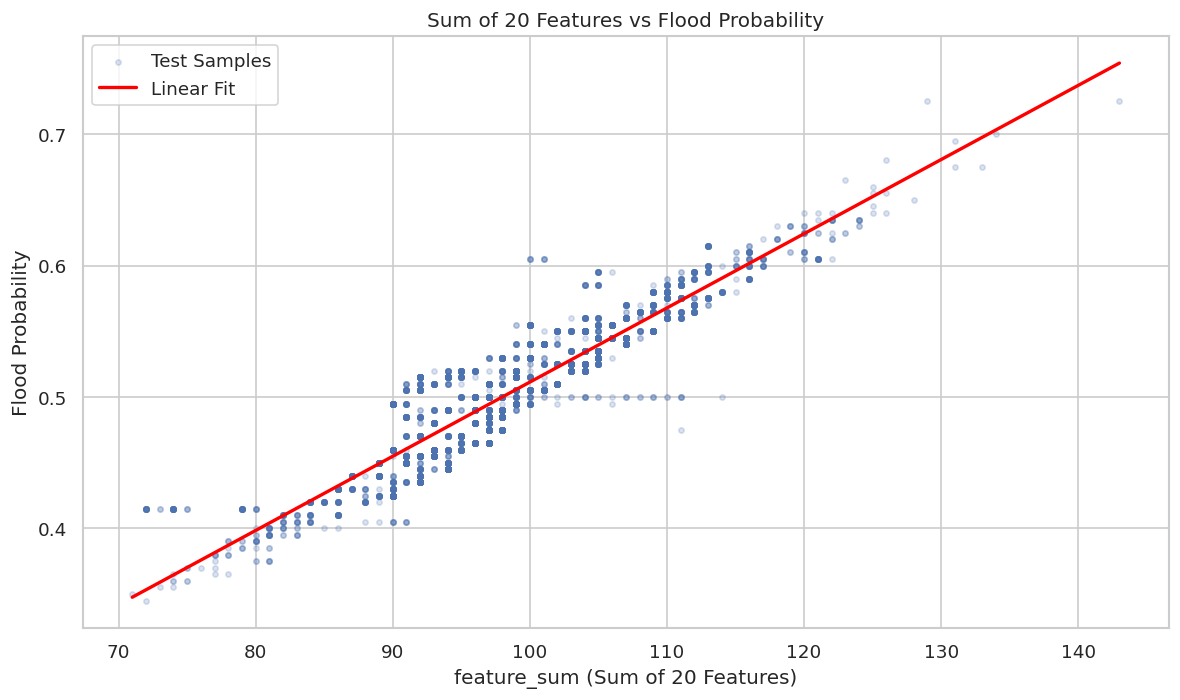

In [40]:
# ========================================
# 40. Feature Sum Experiment
# ========================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

raw_features = list(best_features)

# A：只用 20 個特徵的加總
Xtr_sum = X_train[raw_features].sum(axis=1).to_frame("feature_sum")
Xte_sum = X_test[raw_features].sum(axis=1).to_frame("feature_sum")

sum_model = LinearRegression().fit(Xtr_sum, y_train)
pred_sum = sum_model.predict(Xte_sum)

# B：全部 20 個原始特徵
all_model = LinearRegression().fit(X_train[raw_features], y_train)
pred_all = all_model.predict(X_test[raw_features])

sum_results = pd.DataFrame([
    {
        "Model": "A: feature_sum only",
        "Num Features": 1,
        "MAE": mean_absolute_error(y_test, pred_sum),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_sum)),
        "R2": r2_score(y_test, pred_sum),
    },
    {
        "Model": "B: All 20 features",
        "Num Features": 20,
        "MAE": mean_absolute_error(y_test, pred_all),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_all)),
        "R2": r2_score(y_test, pred_all),
    },
])

print("=== Feature Sum vs All Features (Test Set) ===")
display(sum_results.round(6))

print("feature_sum coefficient:", round(sum_model.coef_[0], 6))
print("feature_sum intercept:", round(sum_model.intercept_, 6))

# 視覺化：feature_sum 與 FloodProbability 的關係（抽樣）
plot_df = pd.DataFrame({
    "feature_sum": Xte_sum["feature_sum"].to_numpy(),
    "FloodProbability": np.asarray(y_test),
}).sample(n=min(5000, len(Xte_sum)), random_state=42)

line_x = np.linspace(plot_df["feature_sum"].min(), plot_df["feature_sum"].max(), 100)
line_y = sum_model.predict(pd.DataFrame({"feature_sum": line_x}))

plt.figure(figsize=(10, 6))
plt.scatter(plot_df["feature_sum"], plot_df["FloodProbability"], alpha=0.2, s=10, label="Test Samples")
plt.plot(line_x, line_y, color="red", linewidth=2, label="Linear Fit")
plt.title("Sum of 20 Features vs Flood Probability")
plt.xlabel("feature_sum (Sum of 20 Features)")
plt.ylabel("Flood Probability")
plt.legend()
plt.tight_layout()
plt.show()

**特徵加總實驗結論**：只用 1 個 `feature_sum` 的測試 R² = **0.844863**，與 20 個特徵的 **0.844877** 僅差 0.000014，MAE、RMSE 也幾乎相同（迴歸式約為 FloodProbability ≈ 0.005646 × feature_sum − 0.053311）。這代表此合成資料的目標值主要由「20 個特徵的總和」決定，也解釋了：(1) 為什麼 OLS 的 20 個係數幾乎相同；(2) 為什麼特徵選擇刪掉任何特徵都會讓 R² 下降；(3) 為什麼網路高分解法都先建立 sum 等列統計特徵，再交給 LightGBM / CatBoost 學習剩下的非線性部分（R² 約 0.869）。

# 6. Deployment（模型部署）

使用全部 `train.csv` 重新訓練最終模型 → 對 `test.csv` 預測並輸出 Kaggle `submission.csv` → 用 joblib 儲存 Pipeline → 提供 `predict_flood()` 函式預測新資料。

**Kaggle 成績**（賽後提交）：Public Score **0.84458**、Private Score **0.84426**（對照 Private Leaderboard 約第 1,845 名）。

In [41]:

# ========================================
# CRISP-DM: Deployment
# 41. Final Model Configuration
# ========================================

import pandas as pd
import numpy as np
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# 前面特徵選擇階段得到的特徵
final_features = list(best_features)

# 以之前測試集評估中表現最好的模型為例
best_model_name = evaluation_df.iloc[0]["Model"]

# statsmodels OLS 與 sklearn LinearRegression
# 本質上都是普通最小平方法
if best_model_name == "OLS":
    best_model_name = "LinearRegression"

print("Final Model:", best_model_name)
print("Number of Features:", len(final_features))
print("Selected Features:", final_features)


Final Model: Ridge
Number of Features: 20
Selected Features: ['MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors']


In [42]:

# ========================================
# 42. Retrain Final Model
# ========================================

# 使用 train.csv 的全部可用資料
df_final = df.drop(
    columns=["id"],
    errors="ignore"
).copy()

# 去除完全重複資料
df_final = df_final.drop_duplicates()

# 去除目標值缺失的資料
df_final = df_final.dropna(
    subset=["FloodProbability"]
)

# 選取最終特徵與目標
X_full = df_final[final_features].copy()
y_full = df_final["FloodProbability"].copy()

# 根據先前選出的模型類型建立新模型
if best_model_name == "LinearRegression":
    estimator = LinearRegression()

elif best_model_name == "Ridge":
    best_alpha = trained_models["Ridge"].named_steps["model"].alpha_
    estimator = Ridge(alpha=best_alpha)

elif best_model_name == "Lasso":
    best_alpha = trained_models["Lasso"].named_steps["model"].alpha_
    estimator = Lasso(
        alpha=best_alpha,
        max_iter=10000,
        random_state=42
    )

else:
    raise ValueError("Unsupported model")

# 建立完整模型 Pipeline
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", estimator)
])

# 使用所有訓練資料重新訓練
final_model.fit(X_full, y_full)

print("Final Model Training Completed!")
print("Model:", best_model_name)
print("Training Samples:", len(X_full))
print("Number of Features:", X_full.shape[1])


Final Model Training Completed!
Model: Ridge
Training Samples: 1117957
Number of Features: 20


In [43]:

# ========================================
# 43. Kaggle Submission
# ========================================

# 讀取 Kaggle test.csv（找不到檔案時會跳出上傳視窗）
test_df = load_csv("test.csv")

# 檢查必要欄位
assert "id" in test_df.columns

missing_columns = [
    col for col in final_features
    if col not in test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing feature columns: {missing_columns}"
    )

# 保留訓練時的特徵順序
X_kaggle = test_df[final_features].copy()

# 使用最終模型預測
test_predictions = final_model.predict(X_kaggle)

# 檢查輸出數量與數值
assert len(test_predictions) == len(test_df)
assert np.isfinite(test_predictions).all()

# 建立 Kaggle Submission
submission = pd.DataFrame({
    "id": test_df["id"],
    "FloodProbability": test_predictions
})

# 儲存 CSV
submission.to_csv(
    "submission.csv",
    index=False
)

print("Submission Shape:", submission.shape)
display(submission.head())

print("\nSubmission file created!")

# 下載檔案
download_file("submission.csv")


Saving test.csv to test.csv
Submission Shape: (745305, 2)


,id,FloodProbability
0,1117957,0.573615
1,1117958,0.455244
2,1117959,0.454743
3,1117960,0.466204
4,1117961,0.466068



Submission file created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:

# ========================================
# 44. Save Model with joblib
# ========================================

import joblib

model_package = {
    "model": final_model,
    "features": final_features,
    "model_name": best_model_name,
    "target": "FloodProbability"
}

# 儲存模型及相關資訊
joblib.dump(
    model_package,
    "flood_prediction_model.joblib"
)

print("Model saved successfully!")

# 測試重新載入
loaded_package = joblib.load(
    "flood_prediction_model.joblib"
)

loaded_model = loaded_package["model"]

# 比較儲存前後的預測結果
original_pred = final_model.predict(
    X_full.head(5)
)

loaded_pred = loaded_model.predict(
    X_full.head(5)
)

np.testing.assert_allclose(
    original_pred,
    loaded_pred
)

print("Model reload verification passed!")

# 下載模型檔案
download_file("flood_prediction_model.joblib")


Model saved successfully!
Model reload verification passed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

# ========================================
# 45. Prediction Function
# ========================================

def predict_flood(input_data):
    """
    使用已儲存模型預測洪水機率。

    Parameters
    ----------
    input_data : dict, list[dict], or DataFrame
        包含模型所需特徵的資料。

    Returns
    -------
    pandas.DataFrame
        FloodProbability 預測結果。
    """

    package = joblib.load(
        "flood_prediction_model.joblib"
    )

    model = package["model"]
    features = package["features"]

    # 單筆資料
    if isinstance(input_data, dict):
        data = pd.DataFrame([input_data])

    # 多筆資料
    elif isinstance(input_data, list):
        data = pd.DataFrame(input_data)

    # DataFrame
    elif isinstance(input_data, pd.DataFrame):
        data = input_data.copy()

    else:
        raise TypeError(
            "Input must be dict, list, or DataFrame"
        )

    # 檢查必要特徵
    missing = [
        col for col in features
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required features: {missing}"
        )

    # 統一欄位順序與資料型態
    data = data[features].apply(
        pd.to_numeric,
        errors="raise"
    )

    # 預測
    predictions = model.predict(data)

    return pd.DataFrame({
        "FloodProbability": predictions
    })


In [46]:

# ========================================
# 46. Example Prediction
# ========================================

# 示範輸入，使用資料集中的一筆特徵
example_input = X_full.iloc[0].to_dict()

print("Example Input:")
print(example_input)

# 執行預測
result = predict_flood(example_input)

print("\nPredicted Flood Probability:")
display(result)

# 多筆預測範例
batch_input = X_full.head(5)

batch_result = predict_flood(batch_input)

print("\nBatch Predictions:")
display(batch_result)


Example Input:
{'MonsoonIntensity': 5, 'TopographyDrainage': 8, 'RiverManagement': 5, 'Deforestation': 8, 'Urbanization': 6, 'ClimateChange': 4, 'DamsQuality': 4, 'Siltation': 3, 'AgriculturalPractices': 3, 'Encroachments': 4, 'IneffectiveDisasterPreparedness': 2, 'DrainageSystems': 5, 'CoastalVulnerability': 3, 'Landslides': 3, 'Watersheds': 5, 'DeterioratingInfrastructure': 4, 'PopulationScore': 7, 'WetlandLoss': 5, 'InadequatePlanning': 7, 'PoliticalFactors': 3}

Predicted Flood Probability:


,FloodProbability
0,0.477557



Batch Predictions:


,FloodProbability
0,0.477557
1,0.477334
2,0.505792
3,0.533990
4,0.353151


**Deployment 說明**

- 模型以 sklearn `Pipeline`（SimpleImputer → StandardScaler → Ridge）整包存成 `flood_prediction_model.joblib`，載入後不需要另外做前處理。
- `predict_flood()` 可接受 dict、list 或 DataFrame，會先檢查 20 個必要欄位再預測。
- 實際應用可以：(1) 包成 FastAPI / Flask API，讓防災系統輸入區域風險指標取得洪水機率；(2) 用 Streamlit 做成互動介面；(3) 每日批次排程計算各區域風險並畫成儀表板。
- 限制：本資料為合成資料，實際部署前必須用真實地區資料重新訓練與驗證，並持續監控資料漂移。

# 7. 結論

1. 依 CRISP-DM 完成資料理解、前處理、特徵選擇、建模、評估與部署。
2. 三種特徵選擇方法都顯示保留 **20 個特徵**最好（CV R² = 0.844959），預測訊號平均分散在每個特徵中。
3. 最終 Ridge 模型測試集 R² = 0.844877、RMSE = 0.020080；Kaggle Public / Private = 0.84458 / 0.84426。
4. 殘差診斷大致符合線性回歸假設，VIF 約 1.0，沒有多重共線性問題；95% 預測區間涵蓋率與理論值一致。
5. 特徵加總實驗顯示目標主要由特徵總和決定；網路高分解法以 sum/mean/std 等統計特徵搭配梯度提升樹，可再提升到約 0.869。